# Universidad Nacional de Colombia  
## Sede Bogotá  
### Facultad de Ingeniería
### Departamento de Ingeniería de Sistemas e Industrial

---

## **Inteligencia Artificial y Mini-robots**

**Título del Taller:**  
*Introducción al Machine Learning*

**Autor:**  
*Juan Jeronimo Gómez Rubiano*  

**Periodo:**  
*2025-2*

**Fecha de entrega:**  
*Octubre 6/2025*

---

*El source code junto a este documento es encuentran disponible en el siguiente repositorio público de github: https://github.com/jujgomezru/ia-minirobots*

## Ejercicio 1

### Considere la figura 6.1. Conforme un data set con resultados de 50.000 multiplicaciones de matrices 2 X 2, generadas aleatoriamente con números enteros entre -20 y 20. Una vez entrenado el modelo, úselo con 10 ejemplos y compare los resultados con los que se producen al realizar la operación analíticamente. Dé conclusiones.

![](cap6/figura1.png)

![Figura 6.](cap6/figura2.png)

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

2025-10-08 20:27:51.077429: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-10-08 20:27:51.111625: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-10-08 20:27:52.094079: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-10-08 20:27:56.924550: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation or

In [5]:
def generate_dataset(num_samples=50000):
    X = []
    y = []
    
    for _ in range(num_samples):
        # Generar matrices 2x2 con enteros entre -20 y 20
        A = np.random.randint(-20, 21, (2, 2))
        B = np.random.randint(-20, 21, (2, 2))
        
        # Calcular multiplicación tradicional
        C = np.dot(A, B)
        
        # Aplanar matrices para entrada/salida del modelo
        X.append(np.concatenate([A.flatten(), B.flatten()]))
        y.append(C.flatten())
    
    return np.array(X), np.array(y)

# 2. Crear y entrenar el modelo
def create_and_train_model(X, y):
    model = Sequential([
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(4)
    ])
    
    model.compile(optimizer='adam',
                 loss='mse',
                 metrics=['mae'])
    
    history = model.fit(X, y, 
                       epochs=50, 
                       batch_size=32,
                       validation_split=0.2,
                       verbose=0)
    return model, history

# 3. Generar dataset y entrenar
print("Generando dataset...")
X, y = generate_dataset(50000)
print("Entrenando modelo...")
model, history = create_and_train_model(X, y)

# 4. Probar con 10 ejemplos nuevos
print("\nComparación con 10 ejemplos nuevos:")
test_results = []
for i in range(10):
    # Generar matrices de prueba
    A_test = np.random.randint(-20, 21, (2, 2))
    B_test = np.random.randint(-20, 21, (2, 2))
    
    # Calcular resultado analítico
    analytical_result = np.dot(A_test, B_test)
    
    # Predecir con el modelo
    model_input = np.concatenate([A_test.flatten(), B_test.flatten()]).reshape(1, -1)
    model_prediction = model.predict(model_input, verbose=0).reshape(2, 2)
    
    # Calcular error
    error = np.mean(np.abs(analytical_result - model_prediction))
    
    test_results.append({
        'A': A_test.copy(),
        'B': B_test.copy(),
        'Analytical': analytical_result.copy(),
        'ML': model_prediction.copy(),
        'Error': error
    })
    
    print(f"\nEjemplo {i+1}:")
    print(f"A:\n{A_test}")
    print(f"B:\n{B_test}")
    print(f"Resultado Analítico:\n{analytical_result}")
    print(f"Predicción ML:\n{model_prediction}")
    print(f"Error promedio: {error:.4f}")

# 5. Análisis de resultados
avg_error = np.mean([r['Error'] for r in test_results])
max_error = np.max([r['Error'] for r in test_results])

print("\n" + "="*50)
print(f"Error promedio en pruebas: {avg_error:.4f}")
print(f"Error máximo en pruebas: {max_error:.4f}")

Generando dataset...
Entrenando modelo...

Comparación con 10 ejemplos nuevos:

Ejemplo 1:
A:
[[14 -6]
 [10 16]]
B:
[[ 1 -5]
 [20 -4]]
Resultado Analítico:
[[-106  -46]
 [ 330 -114]]
Predicción ML:
[[-102.67674  -38.24266]
 [ 314.07904 -111.49616]]
Error promedio: 7.3763

Ejemplo 2:
A:
[[  5 -16]
 [-20  -8]]
B:
[[ -2  -6]
 [ -2 -20]]
Resultado Analítico:
[[ 22 290]
 [ 56 280]]
Predicción ML:
[[ 18.907633 291.65778 ]
 [ 51.08362  278.46408 ]]
Error promedio: 2.8006

Ejemplo 3:
A:
[[  3 -12]
 [-10 -17]]
B:
[[-15   0]
 [  3  10]]
Resultado Analítico:
[[ -81 -120]
 [  99 -170]]
Predicción ML:
[[ -80.76686  -120.164085]
 [  95.05816  -177.69057 ]]
Error promedio: 3.0074

Ejemplo 4:
A:
[[ -6   2]
 [-16  16]]
B:
[[13 18]
 [10 18]]
Resultado Analítico:
[[-58 -72]
 [-48   0]]
Predicción ML:
[[-52.29614    -76.98146   ]
 [-51.27652     -0.30901736]]
Error promedio: 3.5677

Ejemplo 5:
A:
[[11 16]
 [15 12]]
B:
[[-1 -5]
 [18 16]]
Resultado Analítico:
[[277 201]
 [201 117]]
Predicción ML:
[[284.6880

Comenzamos con la importación de librerías necesarias para construir el modelo de Machine Learning multiplicador de matrices. Usamos la librería `tensorflow` para utilizar sus métodos de construcción y entrenamientos de redes neuronales.

Construimos la función `generate_dataset` para construir nuestras matrices aleatorias con el fin de entrenar y testear nuestro modelo de Machine Learning. El constructor de matrices también calcula automáticamente el resultado de la multiplicación con el método `np.dot`, ya que, de manera descriptiva, esta es una operación muy trivial. La matriz C (resultado) será utilizada para medir la aptitud de la red neuronal. 

Luego definimos la función `create_and_train_model` para construir la red neuronal y pasarle los parámetros de entrenamiento. Construimos 4 capas intermedias entre 256 y 32 neuronas, con 4 neuronas de salida, que representan la matriz 2X2 que se propone como solución a la ecuación. Se utiliza el algoritmo de optimización Adam, y el método de mínimos cuadrados como función de pérdida.

A continuación probamos las predicciones del mejor modelo construido durante el entrenamiento. Se decide mantenerse con 50 épocas por el tamaño considerable de la base de datos de entrenamiento, lo que ya hace el tiempo de ejecución del programa bastante significativo. En la corrida de prueba durante la escritura de este notebook, se construye una muestra de 10 multiplicaciones, con un error promedio de 5.2805. Obviamente palidece en comparación con el método analítico, que tiene un error nulo (porque sabe la solución exacta), y consume muchos menos recursos que los métodos de tensorflow. Este ejercicio muestra que incluso una red neuronal compleja, puede no ser la solución óptima si el entrenamiento de la red neuronal no entiende de entrada la lógica del problema a resolver. Esto muestra que el uso de redes neuronales es preferible para problemas complejos, cuya solución analítica, o relación de causalidad entre entradas y salidas no es clara, y se necesitan realizar prediciones razonables para un producto funcional. Por esto es que las RNAs son tan populares para abordar problemas como el lenguaje natural o la computación visual, porque definir las reglas explícitas para resolver este tipo de problemas (por ejemplo, reconocer números escritos a mano) es significativamente complejo, ya que los seres humanos requieren de unas herramientas intrínsecas de reconocimiento de patrones y contexto para resolver estos problemas.

## Ejercicio 2

### Estudie el algoritmo SVM con todo detalle, mejore su documentación y con base en el haga cambios para una aplicación.

Iniciamos definiendo una semilla fija (42), la cual vamos a necesitar en la ejecución de este cuaderno, para permitir la reproducibilidad de datos de una configuración inicial, aunque el objetivo principal del algoritmo es simular el procesamiento de datos aleatorios. 

La directiva `%matplotlib` inline configura el backend de Matplotlib para integración nativa con entornos Jupyter, permitiendo la renderización directa de figuras en el contexto del notebook. Luego configuramos los parámetros tipográficos para asegurar una estética de índole académico, permitiendo legibilidad y coherencia visual.

En el preámbulo también definimos un directorio raíz e identificador de módulo ("svm") para mantener una organización adecuada y reproducible de los archivos generados en la sesión, con fines de facilitar el seguimiento de datos específicos de acuerdo al interés del usuario.

En la función `save_fig` definimos nuestro protocolo estandarizado para la exportación de visualizaciones. Incorporamos mensajes de auto-documentación, optimización de diseño (`tight-layout`), calidad de documentación (resolución de 300 DPI) y uso de .PNG como formato estandarizado, escogido para balancear la calidad de imagen y el tamaño del archivo, importante para la visualización de elementos vectoriales de este algoritmo.

In [27]:
import os

np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "svm"

def save_fig(fig_id, tight_layout=True):
    #path = os.path.join("images",  + ".png")
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig("images", format='png', dpi=300)

Para la implementación del algoritmo vamos a utilizar la librería scikit-learn, particularmente la clase SVC que proporciona la implementación de los Support Vector Machine para problemas de clasificación. Con el módulo datasets importamos conjuntos de datos estandarizados para experimentación y benchmarking.

Para este ejemplo en específico, importamos el conjunto de datos Iris. Este conjunto de datos, introducido por Ronald Fisher en 1936, constituye un benchmark histórico en pattern recognition. Contiene 150 observaciones de tres especies de flores Iris (setosa, versicolor y virginica), con cuatro medidas morfológicas por instancia: longitud y ancho de sépalo, y longitud y ancho de pétalo. Indexamos para extraer características de longitud y ancho del pétalo para nuestro ejercicio. Adicionalmente implementamos una máscara para excluir a la especie "virginica". Esta especie se excluye de este ejemplo para permitir expresar este ejercicio como un problema de clasificación binaria. Se escoge excluir a virginica porque las otras especies son más distintas entre sí, por lo que se facilita el ejercicio de clasificación.

La función `kernel="linear"` especifica un mapeo lineal en el espacio de características, apropiado para problemas con separabilidad lineal. Este kernel calcula el producto punto entre vectores de entrada, generando hiperplanos de decisión. El parámetro `C=float("inf")` establece una penalización infinita por violaciones del margen, forzando una clasificación perfecta en datos linealmente separables. Esta configuración busca el margen máximo estricto (hard-margin SVM), asumiendo separabilidad lineal completa en el conjunto de entrenamiento.

El método `fit()` implementa el algoritmo de optimización que encuentra el hiperplano óptimo maximizando el margen entre clases. Para un kernel lineal, esto involucra la resolución de un problema de programación cuadrática que determina los vectores soporte y los coeficientes del hiperplano de decisión.

In [28]:
from sklearn.svm import SVC
from sklearn import datasets

iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = iris["target"]

setosa_or_versicolor = (y == 0) | (y == 1)
X = X[setosa_or_versicolor]
y = y[setosa_or_versicolor]

# SVM Classifier model
svm_clf = SVC(kernel="linear", C=float("inf"))
svm_clf.fit(X, y)

,C,inf
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


#### Análisis Comparativo de Límites de Decisión en Clasificación SVM: Visualización de Modelos Subóptimos versus Óptimo

Se definen tres hipersuperficies de decisión lineales para propósitos comparativos:

Línea 1: $5*x_0 - 20$ - Pendiente pronunciada con intercepto negativo extremo

Línea 2: $x_0 - 1.8$ - Pendiente unitaria con desplazamiento moderado

Línea 3: $0.1*x_0 + 0.5$ - Pendiente mínima con intercepto cercano al origen

Estos modelos representan aproximaciones lineales subóptimas que, aunque potencialmente capaces de separar las clases, no maximizan el margen de separación entre conjuntos.

La función `plot_svc_decision_boundary` accede a los coeficientes del hiperplano (w) y término de bias (b) del clasificador SVM entrenado. Estos parámetros definen matemáticamente la superficie de decisión en el espacio de características. La transformación algebraica $x_1 = \frac{-w_0}{w_1} * x_0 - \frac{b}{w_1}$ deriva de la ecuación del hiperplano $w_0*x_0 + w_1*x_1 + b = 0$, permitiendo visualizar la frontera de decisión como función lineal en dos dimensiones. El cálculo $margin = \frac{1}{w[1]}$ determina la distancia perpendicular desde el hiperplano de decisión hasta los límites del margen. Las líneas gutter_up y gutter_down representan los bordes del corredor de separación donde se ubican los vectores soporte. Los vectores soporte (`support_vectors_`) se visualizan con marcadores destacados (#FFAAAA).

A continuación, visualizamos dos paneles. En ambos paneles se visualizan los datos, los cuadrados azules representan a la especie Versicolor, y los círculos amarillos a la especie Setosa:

En el panel izquierdo, se visualizan tres líneas, que representan los tres modelos lineales subóptimos decididos de manera arbitraria previamente.

En el panel derecho, se aplica la función de visualización con el clasificador SVM entrenado. La línea central es el hiperplano de decisión óptimo. Las líneas punteadas representan los márgenes de los posibles hiperplanos de decisión. Se incluye la visualización de puntos que se encuentran en el límite del clasificador. Guardamos el archivo con la función `save_fig` para poder descargar el resultado.

Saving figure large_margin_classification_plot


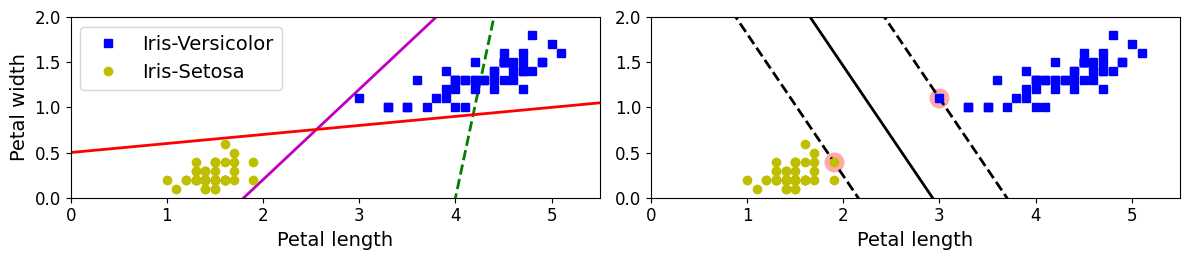

In [29]:
# Bad models
x0 = np.linspace(0, 5.5, 200)
pred_1 = 5*x0 - 20
pred_2 = x0 - 1.8
pred_3 = 0.1 * x0 + 0.5

def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    # At the decision boundary, w0*x0 + w1*x1 + b = 0
    # => x1 = -w0/w1 * x0 - b/w1
    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0]/w[1] * x0 - b/w[1]

    margin = 1/w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    svs = svm_clf.support_vectors_
    plt.scatter(svs[:, 0], svs[:, 1], s=180, facecolors='#FFAAAA')
    plt.plot(x0, decision_boundary, "k-", linewidth=2)
    plt.plot(x0, gutter_up, "k--", linewidth=2)
    plt.plot(x0, gutter_down, "k--", linewidth=2)

plt.figure(figsize=(12,2.7))

plt.subplot(121)
plt.plot(x0, pred_1, "g--", linewidth=2)
plt.plot(x0, pred_2, "m-", linewidth=2)
plt.plot(x0, pred_3, "r-", linewidth=2)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris-Versicolor")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris-Setosa")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="upper left", fontsize=14)
plt.axis([0, 5.5, 0, 2])

plt.subplot(122)
plot_svc_decision_boundary(svm_clf, 0, 5.5)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo")
plt.xlabel("Petal length", fontsize=14)
plt.axis([0, 5.5, 0, 2])

save_fig("large_margin_classification_plot")
plt.show()

#### Efecto del Escalado de Características en Máquinas de Vectores de Soporte

El conjunto de datos artificial se compone de cuatro observaciones bidimensionales con asignaciones binarias de clase. Las características presentan una disparidad deliberada en sus escalas: la primera característica varía en el rango [1,5] mientras la segunda característica exhibe variaciones en el intervalo [20,80]. Esta configuración permite observar directamente el impacto de dominios numéricos dispares en la geometría del hiperplano de decisión.

Inicialmente se entrena un clasificador SVM lineal con los parámetros definidos previamente. El resultado visual muestra un hiperplano de decisión que presenta sensibilidad predominante a la característica de mayor magnitud ($x_1$), generando un límite de clasificación con orientación cercana a la horizontal que prioriza incorrectamente la variable con escala numérica superior.

Posteriormente se aplica transformación de escalado mediante la clase `StandardScaler` de scikit-learn, que implementa estandarización Z-score. Esta transformación calcula estadísticos muestrales según la relación:

$z=\frac{x−μ}{σ}$
 
donde μ representa la media muestral y σ la desviación estándar. La estandarización genera características con distribución de media cero y varianza unitaria, equilibrando la contribución potencial de cada dimensión al criterio de optimización.

El mismo clasificador SVM se reentrena utilizando el conjunto de datos transformado, manteniendo idénticos hiperparámetros para aislamiento de variables. La solución resultante exhibe un hiperplano de decisión con orientación sustancialmente diferente, ahora reflejando una ponderación balanceada entre ambas características. Los márgenes de separación adoptan una configuración geométrica que maximiza la distancia entre clases considerando ambas dimensiones en igualdad de condiciones numéricas.

La diferencia en la orientación del hiperplano y la localización de los vectores soporte evidencia cómo las disparidades de escala pueden distorsionar la métrica de distancia euclidiana fundamental para el principio de margen máximo.

Saving figure sensitivity_to_feature_scales_plot


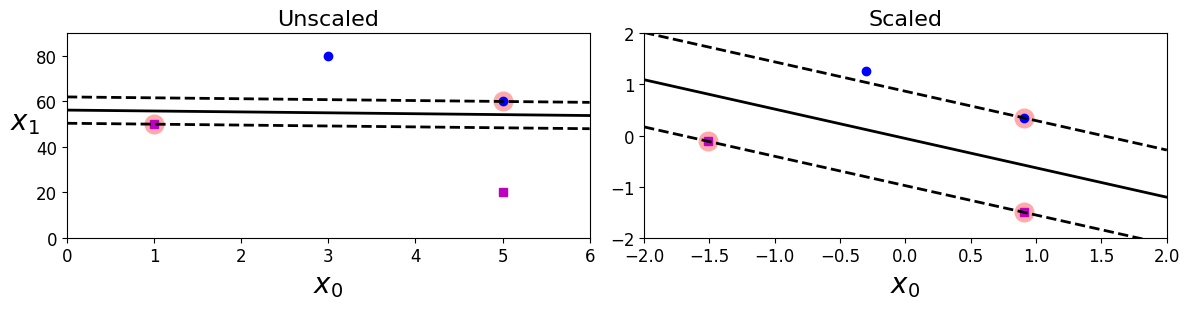

In [30]:
Xs = np.array([[1, 50], [5, 20], [3, 80], [5, 60]]).astype(np.float64)
ys = np.array([0, 0, 1, 1])
svm_clf = SVC(kernel="linear", C=100)
svm_clf.fit(Xs, ys)

plt.figure(figsize=(12,3.2))
plt.subplot(121)
plt.plot(Xs[:, 0][ys==1], Xs[:, 1][ys==1], "bo")
plt.plot(Xs[:, 0][ys==0], Xs[:, 1][ys==0], "ms")
plot_svc_decision_boundary(svm_clf, 0, 6)
plt.xlabel("$x_0$", fontsize=20)
plt.ylabel("$x_1$  ", fontsize=20, rotation=0)
plt.title("Unscaled", fontsize=16)
plt.axis([0, 6, 0, 90])

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(Xs)
svm_clf.fit(X_scaled, ys)

plt.subplot(122)
plt.plot(X_scaled[:, 0][ys==1], X_scaled[:, 1][ys==1], "bo")
plt.plot(X_scaled[:, 0][ys==0], X_scaled[:, 1][ys==0], "ms")
plot_svc_decision_boundary(svm_clf, -2, 2)
plt.xlabel("$x_0$", fontsize=20)
plt.title("Scaled", fontsize=16)
plt.axis([-2, 2, -2, 2])

save_fig("sensitivity_to_feature_scales_plot")

#### Sensibilidad de las Máquinas de Vectores de Soporte a Valores Atípicos

El presente análisis examina la vulnerabilidad de los clasificadores SVM de margen máximo frente a observaciones atípicas en el conjunto de entrenamiento. Se diseña un experimento controlado que introduce puntos aberrantes estratégicamente posicionados para evaluar cómo estas observaciones pueden distorsionar significativamente la geometría del hiperplano de decisión.

Se construyen dos escenarios experimentales mediante la incorporación de valores atípicos diferentes al conjunto de datos original de Iris. Cada escenario introduce una única observación atípica en la clase Setosa, pero en posiciones espaciales distintas que generan impactos cualitativamente diferentes en el proceso de optimización del modelo.

El primer escenario ($Xo_1$, $yo_1$) incorpora un valor atípico ubicado en la región morfológica típicamente asociada a la clase Versicolor, creando una situación de no separabilidad lineal. El segundo escenario ($Xo_2$, $yo_2$) introduce un valor atípico en los límites inferiores del espacio de características, manteniendo técnicamente la separabilidad lineal pero forzando una reconfiguración sustancial del hiperplano.

Se implementa un clasificador SVM lineal, configurado para aproximar el comportamiento de margen máximo estricto. Esta elección de hiperparámetro deliberadamente elevada minimiza la tolerancia a violaciones del margen, maximizando así la sensibilidad del modelo a perturbaciones en los datos de entrenamiento. El modelo se entrena exclusivamente sobre el segundo escenario $Xo_2$, $yo_2$, permitiendo la evaluación comparativa del impacto diferencial según la posición espacial del valor atípico.

El panel izquierdo ilustra una configuración donde la introducción de un valor atípico en región de superposición potencial vuelve matemáticamente imposible la separación lineal perfecta.

El panel derecho demuestra cómo un valor atípico periférico, aunque técnicamente preserva la separabilidad lineal, induce una reorientación significativa del hiperplano de decisión. La solución resultante muestra un margen sustancialmente reducido y una localización subóptima del límite de clasificación, evidenciando la sensibilidad extrema del principio de margen máximo a observaciones individuales en configuraciones de baja regularización.

Saving figure sensitivity_to_outliers_plot


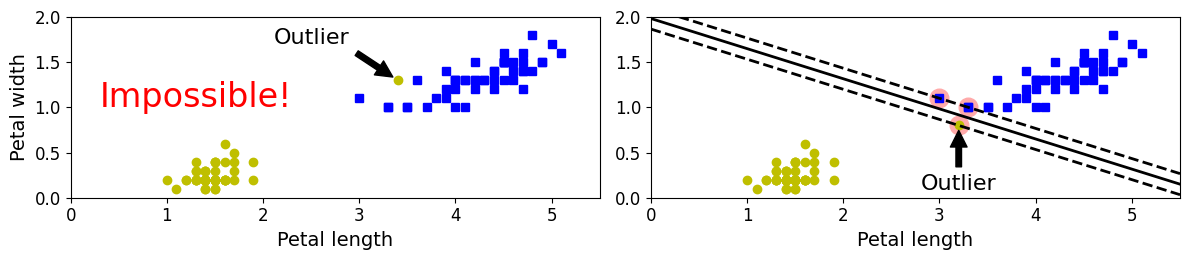

In [31]:
X_outliers = np.array([[3.4, 1.3], [3.2, 0.8]])
y_outliers = np.array([0, 0])
Xo1 = np.concatenate([X, X_outliers[:1]], axis=0)
yo1 = np.concatenate([y, y_outliers[:1]], axis=0)
Xo2 = np.concatenate([X, X_outliers[1:]], axis=0)
yo2 = np.concatenate([y, y_outliers[1:]], axis=0)

svm_clf2 = SVC(kernel="linear", C=10**9)
svm_clf2.fit(Xo2, yo2)

plt.figure(figsize=(12,2.7))

plt.subplot(121)
plt.plot(Xo1[:, 0][yo1==1], Xo1[:, 1][yo1==1], "bs")
plt.plot(Xo1[:, 0][yo1==0], Xo1[:, 1][yo1==0], "yo")
plt.text(0.3, 1.0, "Impossible!", fontsize=24, color="red")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.annotate("Outlier",
             xy=(X_outliers[0][0], X_outliers[0][1]),
             xytext=(2.5, 1.7),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.1),
             fontsize=16,
            )
plt.axis([0, 5.5, 0, 2])

plt.subplot(122)
plt.plot(Xo2[:, 0][yo2==1], Xo2[:, 1][yo2==1], "bs")
plt.plot(Xo2[:, 0][yo2==0], Xo2[:, 1][yo2==0], "yo")
plot_svc_decision_boundary(svm_clf2, 0, 5.5)
plt.xlabel("Petal length", fontsize=14)
plt.annotate("Outlier",
             xy=(X_outliers[1][0], X_outliers[1][1]),
             xytext=(3.2, 0.08),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.1),
             fontsize=16,
            )
plt.axis([0, 5.5, 0, 2])

save_fig("sensitivity_to_outliers_plot")
plt.show()

#### Implementación de Pipelines para Clasificación SVM con Regularización Variable

Se establece un escenario de clasificación para discriminar la especie Iris-Virginica frente a las demás especies del conjunto de datos Iris. La variable objetivo se transforma en una representación binaria donde el valor 1.0 indica pertenencia a Iris-Virginica y 0.0 representa las otras especies, como ya explicamos, preferimos la aplicación de clasificadores lineales a problemas de clasificación binaria.

Se implementa un pipeline modular que integra secuencialmente dos componentes fundamentales: una etapa de preprocesamiento mediante `StandardScaler` para estandarización de características, seguida de un clasificador `LinearSVC` con función de pérdida `hinge`. La elección de la pérdida hinge corresponde a la formulación canónica de Máquinas de Vectores de Soporte, optimizando directamente el margen de clasificación.

In [32]:
import numpy as np
from sklearn import datasets
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = (iris["target"] == 2).astype(np.float64)  # Iris-Virginica

svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("linear_svc", LinearSVC(C=1, loss="hinge", random_state=42)),
    ])

svm_clf.fit(X, y)

,steps,"[('scaler', ...), ('linear_svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,loss,'hinge'
,dual,'auto'
,tol,0.0001


#### Proceso de Inferencia y Predicción

La operación de predicción se aplica a una nueva observación con longitud de pétalo 5.5 cm y ancho de pétalo 1.7 cm. El pipeline ejecuta automáticamente la transformación de escalado sobre estas medidas antes de propagarlas through el clasificador entrenado. El resultado constituye una predicción binaria que indica la pertenencia probabilística a la clase Iris-Virginica.

In [33]:
svm_clf.predict([[5.5, 1.7]])

array([1.])

#### Estudio Comparativo de Intensidades de Regularización

Se diseña un experimento controlado para evaluar el impacto del parámetro de regularización C en la geometría del hiperplano de decisión. Se instancian dos configuraciones de `LinearSVC` idénticas en arquitectura pero con valores de C significativamente diferentes: `C=1` representa regularización moderada, mientras `C=100` configura un modelo con penalización sustancialmente menor a las violaciones del margen.

Ambos clasificadores se encapsulan en pipelines que comparten la misma instancia de `StandardScaler`, asegurando consistencia en las transformaciones de preprocesamiento aplicadas durante el entrenamiento. Esta configuración experimental permite aislar el efecto del hiperparámetro C como variable independiente, controlando potenciales fuentes de variación en el proceso de estandarización.

In [34]:
scaler = StandardScaler()
svm_clf1 = LinearSVC(C=1, loss="hinge", random_state=42)
svm_clf2 = LinearSVC(C=100, loss="hinge", random_state=42)

scaled_svm_clf1 = Pipeline([
        ("scaler", scaler),
        ("linear_svc", svm_clf1),
    ])
scaled_svm_clf2 = Pipeline([
        ("scaler", scaler),
        ("linear_svc", svm_clf2),
    ])

scaled_svm_clf1.fit(X, y)
scaled_svm_clf2.fit(X, y)

/home/jujgomezru/.local/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,steps,"[('scaler', ...), ('linear_svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,loss,'hinge'
,dual,'auto'
,tol,0.0001


#### Metodología de Entrenamiento Comparativo

Tras el entrenamiento con datos estandarizados, se realiza una transformación inversa de los parámetros del modelo para interpretar la solución en las unidades de medida originales. Este proceso implica recalcular los coeficientes del hiperplano (w) y los términos de intercepto (b) mediante operaciones algebraicas que revierten las transformaciones de escalado. La conversión se fundamenta en las propiedades de invarianza de las transformaciones lineales aplicadas durante la estandarización, permitiendo expresar la frontera de decisión en el dominio natural de las variables.

La identificación de vectores soporte se implementa mediante evaluación de las condiciones de Karush-Kuhn-Tucker, específicamente verificando observaciones que satisfacen la restricción de margen unitario. Dado que la implementación LinearSVC no almacena automáticamente estos vectores, se aplica un filtro basado en la función de decisión para detectar instancias críticas que definen geométricamente el corredor de separación entre clases.

In [35]:
# Convert to unscaled parameters
b1 = svm_clf1.decision_function([-scaler.mean_ / scaler.scale_])
b2 = svm_clf2.decision_function([-scaler.mean_ / scaler.scale_])
w1 = svm_clf1.coef_[0] / scaler.scale_
w2 = svm_clf2.coef_[0] / scaler.scale_
svm_clf1.intercept_ = np.array([b1])
svm_clf2.intercept_ = np.array([b2])
svm_clf1.coef_ = np.array([w1])
svm_clf2.coef_ = np.array([w2])

# Find support vectors (LinearSVC does not do this automatically)
t = y * 2 - 1
support_vectors_idx1 = (t * (X.dot(w1) + b1) < 1).ravel()
support_vectors_idx2 = (t * (X.dot(w2) + b2) < 1).ravel()
svm_clf1.support_vectors_ = X[support_vectors_idx1]
svm_clf2.support_vectors_ = X[support_vectors_idx2]

#### Análisis Comparativo de Estrategias de Regularización

La visualización dual contrasta explícitamente el comportamiento de dos configuraciones de regularización en el espacio de características original. El panel izquierdo presenta la solución obtenida con parámetro C=1, mostrando un hiperplano de decisión que prioriza la maximización del margen de separación. Esta configuración genera un corredor de clasificación amplio que promueve robustez frente a variaciones en los datos, potencialmente a expensas de precisión en clasificación de observaciones cercanas a la frontera.

El panel derecho ilustra la solución correspondiente a C=100, donde el énfasis se desplaza hacia la clasificación precisa de instancias individuales. El margen resultante se reduce significativamente, reflejando la mayor penalización asignada a violaciones del mismo. Esta configuración produce una frontera de decisión más compleja que se adapta estrechamente a la distribución observada en el conjunto de entrenamiento.

La comparación visual revela cómo el parámetro de regularización C controla directamente el trade-off entre bias y varianza en el modelo. Márgenes amplios (C bajo) favorecen generalización y estabilidad, mientras márgenes estrechos (C alto) priorizan ajuste a patrones específicos en los datos de entrenamiento. La posición y cantidad de vectores soporte varía sustancialmente entre ambas configuraciones, demostrando la sensibilidad de la solución a este hiperparámetro crítico.

La representación gráfica en el dominio original de petal length y petal width facilita la interpretación biológica de los resultados, permitiendo correlacionar las fronteras de decisión con mediciones morfológicas concretas de las especies Iris-Virginica e Iris-Versicolor.

Saving figure regularization_plot


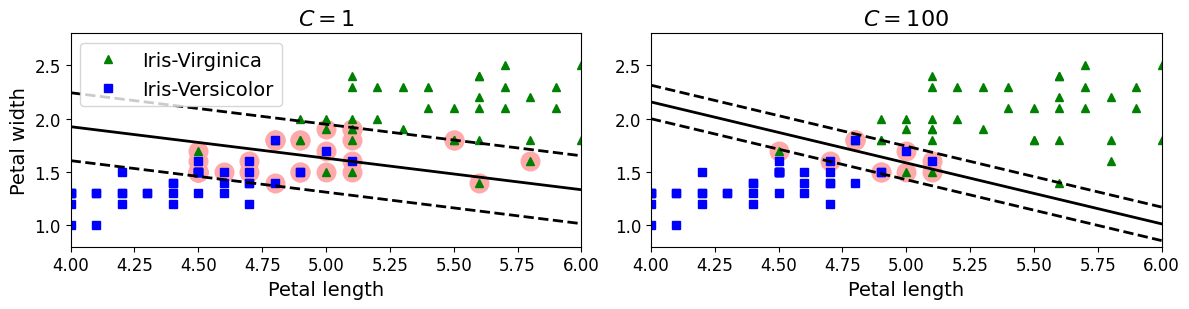

In [36]:
plt.figure(figsize=(12,3.2))
plt.subplot(121)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^", label="Iris-Virginica")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs", label="Iris-Versicolor")
plot_svc_decision_boundary(svm_clf1, 4, 6)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="upper left", fontsize=14)
plt.title("$C = {}$".format(svm_clf1.C), fontsize=16)
plt.axis([4, 6, 0.8, 2.8])

plt.subplot(122)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
plot_svc_decision_boundary(svm_clf2, 4, 6)
plt.xlabel("Petal length", fontsize=14)
plt.title("$C = {}$".format(svm_clf2.C), fontsize=16)
plt.axis([4, 6, 0.8, 2.8])

save_fig("regularization_plot")

#### Transformación de Características para Separabilidad Lineal

Se genera un conjunto de datos sintético unidimensional diseñado específicamente para demostrar las limitaciones de la clasificación lineal en espacios de baja dimensionalidad. Nueve puntos equidistantes se distribuyen en el intervalo [-4, 4], con asignaciones de clase que siguen un patrón no lineal: los puntos extremos pertenecen a la clase 0, mientras los puntos centrales se asignan a la clase 1, creando una configuración donde ninguna frontera lineal unidimensional puede separar perfectamente ambas clases.

Mediante una transformación polinomial de segundo orden, se mapea el conjunto de datos unidimensional original a un espacio bidimensional, donde la segunda dimensión corresponde al cuadrado de la coordenada original ($x_₂ = x_{₁}^{2}$). Esta transformación convierte la relación no separable en el espacio unidimensional en una configuración linealmente separable en el espacio bidimensional, demostrando el principio fundamental detrás del truco del kernel en Máquinas de Vectores de Soporte.

El panel izquierdo presenta la configuración original en una dimensión, donde los puntos de clase 0 (cuadrados azules) y clase 1 (triángulos verdes) se superponen a lo largo del eje $x_₁$. La imposibilidad de trazar un umbral lineal que separe ambas clases resulta evidente, ilustrando la necesidad de transformaciones no lineales para ciertos problemas de clasificación.

El panel derecho muestra la proyección resultante en el espacio de características expandido, donde los puntos ahora forman una parábola. En este nuevo espacio, las clases se organizan de manera que una frontera lineal simple (representada por la línea roja discontinua en $x_₂ = 6.5$) puede separarlas perfectamente. Esta transformación revela cómo el aumento dimensional puede convertir problemas no lineales en linealmente separables.

Saving figure higher_dimensions_plot


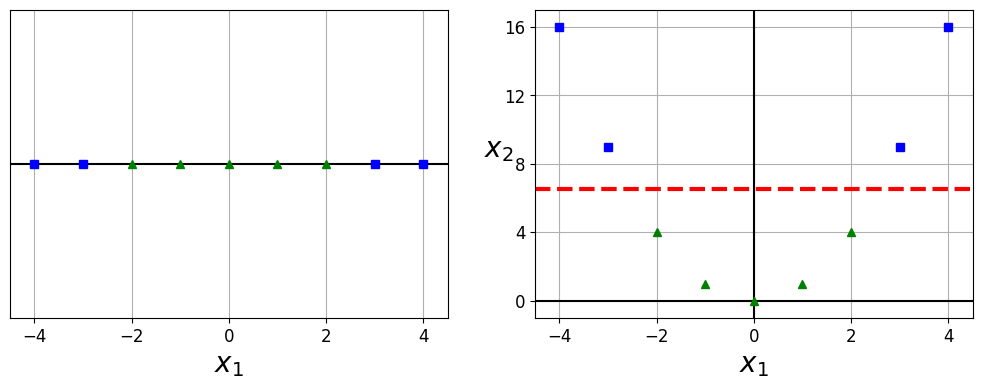

In [37]:
X1D = np.linspace(-4, 4, 9).reshape(-1, 1)
X2D = np.c_[X1D, X1D**2]
y = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

plt.figure(figsize=(11, 4))

plt.subplot(121)
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.plot(X1D[:, 0][y==0], np.zeros(4), "bs")
plt.plot(X1D[:, 0][y==1], np.zeros(5), "g^")
plt.gca().get_yaxis().set_ticks([])
plt.xlabel(r"$x_1$", fontsize=20)
plt.axis([-4.5, 4.5, -0.2, 0.2])

plt.subplot(122)
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(X2D[:, 0][y==0], X2D[:, 1][y==0], "bs")
plt.plot(X2D[:, 0][y==1], X2D[:, 1][y==1], "g^")
plt.xlabel(r"$x_1$", fontsize=20)
plt.ylabel(r"$x_2$", fontsize=20, rotation=0)
plt.gca().get_yaxis().set_ticks([0, 4, 8, 12, 16])
plt.plot([-4.5, 4.5], [6.5, 6.5], "r--", linewidth=3)
plt.axis([-4.5, 4.5, -1, 17])

plt.subplots_adjust(right=1)

save_fig("higher_dimensions_plot", tight_layout=False)
plt.show()

#### Clasificación de Datos No Lineales mediante Máquinas de Vectores de Soporte con Características Polinomiales

Se utiliza el generador `make_moons` de scikit-learn para crear un conjunto de datos sintético que simula un problema de clasificación binaria con estructura no lineal compleja. La configuración especifica 100 observaciones con un nivel de ruido de 0.15, introduciendo variabilidad estocástica controlada que refleja condiciones realistas donde las clases no son perfectamente separables. La representación visual mediante la función `plot_dataset` revela la disposición característica de dos grupos semilunares entrelazados, donde los patrones de clase 0 (cuadrados azules) y clase 1 (triángulos verdes) se distribuyen en formaciones curvadas que imposibilitan la separación mediante fronteras lineales simples.

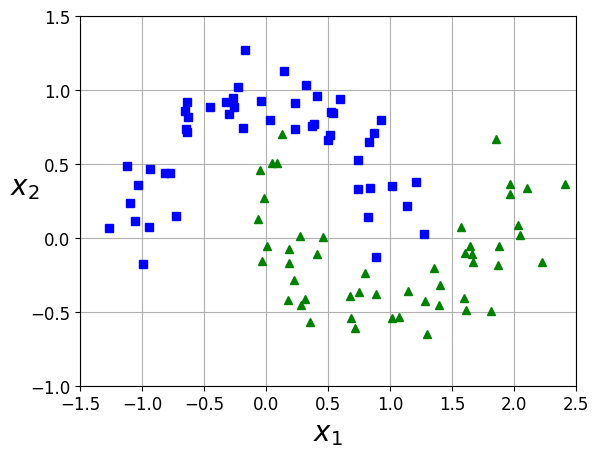

In [38]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=100, noise=0.15, random_state=42)

def plot_dataset(X, y, axes):
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")
    plt.axis(axes)
    plt.grid(True, which='both')
    plt.xlabel(r"$x_1$", fontsize=20)
    plt.ylabel(r"$x_2$", fontsize=20, rotation=0)

plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
plt.show()

#### Implementación de Pipeline con Transformación Polinomial

Se construye un pipeline de procesamiento que integra secuencialmente tres componentes fundamentales para abordar la no linealidad inherente en los datos. La primera etapa aplica una transformación polinomial de tercer grado mediante `PolynomialFeatures`, expandiendo el espacio de características original bidimensional a uno de mayor dimensionalidad que incluye términos polinomiales hasta el grado tres. Esta expansión permite capturar relaciones no lineales entre variables mediante la incorporación de interacciones y términos cuadráticos y cúbicos.

La segunda etapa estandariza las características transformadas utilizando `StandardScaler`, asegurando que todas las dimensiones en el espacio polinomial expandido contribuyan equitativamente al proceso de optimización. La etapa final implementa un clasificador LinearSVC con función de pérdida hinge y parámetro de regularización `C=10`, configurando un modelo de margen máximo que opera en el espacio de características polinomial transformado.

In [39]:
from sklearn.datasets import make_moons
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

polynomial_svm_clf = Pipeline([
        ("poly_features", PolynomialFeatures(degree=3)),
        ("scaler", StandardScaler()),
        ("svm_clf", LinearSVC(C=10, loss="hinge", random_state=42))
    ])

polynomial_svm_clf.fit(X, y)

/home/jujgomezru/.local/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,steps,"[('poly_features', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,degree,3
,interaction_only,False
,include_bias,True
,order,'C'
,copy,True
,with_mean,True
,with_std,True


#### Visualización de Regiones de Decisión y Función de Clasificación

La función `plot_predictions` genera una representación comprehensiva del comportamiento del clasificador mediante técnicas de muestreo espacial y visualización de contornos. Se crea una malla densa de puntos en el espacio de características original, para los cuales se calculan tanto las predicciones discretas como los valores continuos de la función de decisión del modelo SVM entrenado.

La visualización resultante superpone múltiples capas de información: las regiones de clasificación se representan mediante colores sólidos con transparencia, mientras los niveles de la función de decisión se muestran como contornos sutiles que revelan la confianza del modelo en diferentes zonas del espacio de características. La superposición del conjunto de datos original sobre estas regiones permite evaluar visualmente la calidad del ajuste, mostrando cómo la frontera de decisión polinomial captura la estructura curvilínea subyacente en los datos.

La solución demuestra la efectividad del enfoque de kernel implícito mediante transformación explícita de características, donde la combinación de expansión polinomial y clasificación lineal en el espacio transformado provee un mecanismo computacionalmente eficiente para resolver problemas de clasificación no lineal sin recurrir a kernels más complejos.

Saving figure moons_polynomial_svc_plot


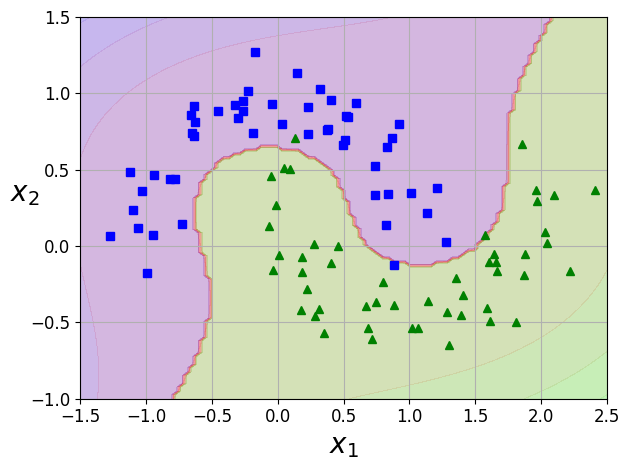

In [40]:
def plot_predictions(clf, axes):
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X).reshape(x0.shape)
    y_decision = clf.decision_function(X).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)

plot_predictions(polynomial_svm_clf, [-1.5, 2.5, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])

save_fig("moons_polynomial_svc_plot")
plt.show()

#### Implementación de SVM con kernel polinomial

Se implementa un clasificador SVM que utiliza el truco del kernel para operar implícitamente en espacios de características de alta dimensionalidad sin requerir transformación explícita. El pipeline integra estandarización de características seguida de un clasificador SVC con kernel polinomial de tercer grado, coeficiente independiente (`coef0`) de 1 y parámetro de regularización `C=5`. Esta configuración representa un balance entre capacidad de modelado de no linealidades y control de sobreajuste, donde el kernel polinomial calcula similitudes entre instancias mediante la función $(γ⟨x, x'⟩ + r)^{d}$ sin necesidad de computar explícitamente las características polinomiales expandidas.

In [41]:
from sklearn.svm import SVC

poly_kernel_svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", SVC(kernel="poly", degree=3, coef0=1, C=5))
    ])
poly_kernel_svm_clf.fit(X, y)

,steps,"[('scaler', ...), ('svm_clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,5
,kernel,'poly'
,degree,3
,gamma,'scale'


#### Configuración de Modelo con Kernel Polinomial de Alto Grado

Se construye un clasificador comparativo que emplea un kernel polinomial de décimo grado con coeficiente independiente significativamente mayor (`coef0=100`), manteniendo el mismo nivel de regularización (`C=5`). Esta configuración incrementa sustancialmente la capacidad de representación del modelo al permitir fronteras de decisión más complejas y altamente no lineales. El parámetro `coef0` controla la influencia de términos de alto grado en la función del kernel, donde valores elevados otorgan mayor peso a componentes polinomiales superiores, potencialmente capturando patrones más intricados a riesgo de aumentar sensibilidad a ruido en los datos.

In [42]:
poly100_kernel_svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", SVC(kernel="poly", degree=10, coef0=100, C=5))
    ])
poly100_kernel_svm_clf.fit(X, y)

,steps,"[('scaler', ...), ('svm_clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,5
,kernel,'poly'
,degree,10
,gamma,'scale'


#### Análisis Comparativo de Comportamiento de Modelos

La visualización dual contrasta el desempeño de ambas configuraciones sobre el conjunto de datos "moons", revelando el impacto de los hiperparámetros del kernel en la geometría de las fronteras de decisión. El panel izquierdo (d=3, r=1, C=5) muestra una frontera de decisión suavemente curvada que sigue aproximadamente la estructura subyacente de los datos, demostrando la capacidad del kernel polinomial cúbico para capturar relaciones no lineales básicas mientras mantiene cierta regularización implícita.

El panel derecho (d=10, r=100, C=5) exhibe una frontera de decisión notablemente más compleja con contornos intricados que se ajustan estrechamente a la distribución específica de las observaciones de entrenamiento. Esta configuración de alto grado polinomial genera regiones de clasificación más fragmentadas que pueden reflejar tanto la captura de patrones complejos genuinos como potencial sobreajuste a peculiaridades del conjunto de entrenamiento.

La comparación ilustra el trade-off fundamental entre sesgo y varianza en el contexto de kernels polinomiales: grados bajos producen modelos más simples con mejor generalización pero limitada capacidad expresiva, mientras grados altos permiten modelar relaciones complejas a expensas de mayor sensibilidad a fluctuaciones en los datos. El coeficiente independiente actúa como parámetro de ajuste fino que modula la influencia relativa de diferentes órdenes polinomiales en la función de decisión final.

Saving figure moons_kernelized_polynomial_svc_plot


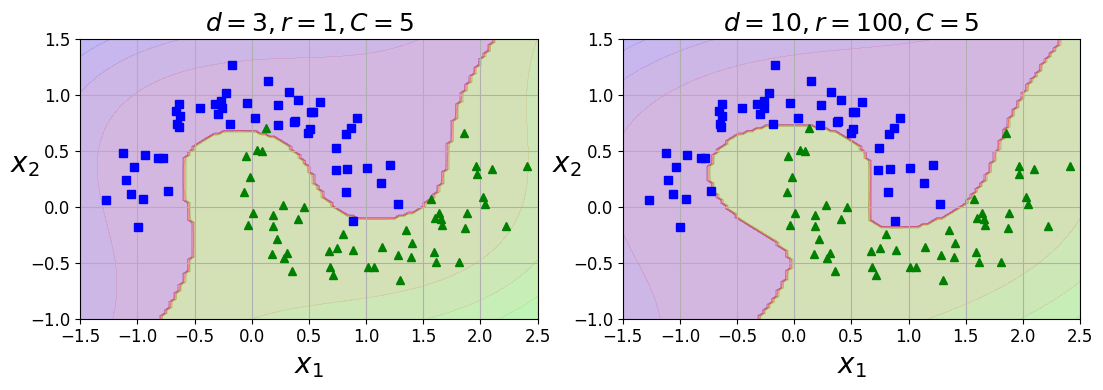

In [43]:
plt.figure(figsize=(11, 4))

plt.subplot(121)
plot_predictions(poly_kernel_svm_clf, [-1.5, 2.5, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
plt.title(r"$d=3, r=1, C=5$", fontsize=18)

plt.subplot(122)
plot_predictions(poly100_kernel_svm_clf, [-1.5, 2.5, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
plt.title(r"$d=10, r=100, C=5$", fontsize=18)

save_fig("moons_kernelized_polynomial_svc_plot")
plt.show()

#### El Método del Kernel con Funciones de Base Radial

Se implementa la función `gaussian_rbf` que calcula la similitud kernel entre puntos de datos y puntos de referencia (landmarks) mediante la función de base radial gaussiana. Esta función transforma puntos en el espacio original a un espacio de características de dimensión infinita donde las relaciones no lineales pueden volverse linealmente separables. La formulación matemática se basa en el cálculo de distancias euclidianas exponencialmente ponderadas, donde el parámetro gamma controla el alcance de influencia de cada punto de referencia, determinando la rapidez con la que la similitud decae con la distancia.

Se establece un valor gamma de 0.3 para regular el ancho de las funciones de base radial, creando dos landmarks estratégicamente posicionados en -2 y 1 a lo largo del eje unidimensional original. Sobre una malla de 200 puntos equidistantes, se calculan las transformaciones kernel que generan dos nuevas dimensiones de características ($x_2$ y $x_3$), cada una representando la similitud de los puntos originales con respecto a uno de los landmarks. Esta transformación convierte el conjunto de datos unidimensional no linealmente separable en un conjunto bidimensional donde emerge separabilidad lineal.

El panel izquierdo ilustra el conjunto de datos original en una dimensión, superponiendo las curvas de las dos funciones de base radial centradas en los landmarks. Los puntos de clase 0 (cuadrados azules) y clase 1 (triángulos verdes) se muestran distribuidos a lo largo del eje x₁, mientras las curvas gaussianas (verde discontinuo y azul punteado) representan las funciones de similitud que mapean cada punto original a su correspondiente valor de similitud con cada landmark. La anotación destaca un punto específico y su proyección simultánea en ambas funciones de similitud.

El panel derecho muestra el resultado de la transformación kernel, donde cada instancia original se representa ahora por sus coordenadas (x₂, x₃) en el nuevo espacio de características. En este espacio transformado, las clases previamente entrelazadas en una dimensión se organizan en conglomerados claramente separables mediante una frontera lineal (representada por la línea roja discontinua). La anotación φ(x) enfatiza la naturaleza de la transformación kernel aplicada a cada observación.

Significado Conceptual del Método Kernel

Esta visualización demuestra el principio fundamental detrás de las Máquinas de Vectores de Soporte con kernel RBF: mediante la transformación implícita a espacios de alta dimensionalidad a través de funciones de similitud, problemas complejos no lineales se convierten en linealmente separables. El parámetro gamma actúa como control crítico que determina el balance entre flexibilidad del modelo y generalización, donde valores bajos producen fronteras de decisión suaves mientras valores altos generan modelos más complejos que pueden capturar patrones intricados pero con mayor riesgo de sobreajuste.

La línea de decisión lineal en el espacio transformado corresponde a una frontera de decisión no lineal compleja cuando se proyecta de regreso al espacio original, ilustrando la potencia del approach kernel para modelar relaciones no lineales sin requerir computación explícita en espacios de alta dimensionalidad.

Saving figure kernel_method_plot


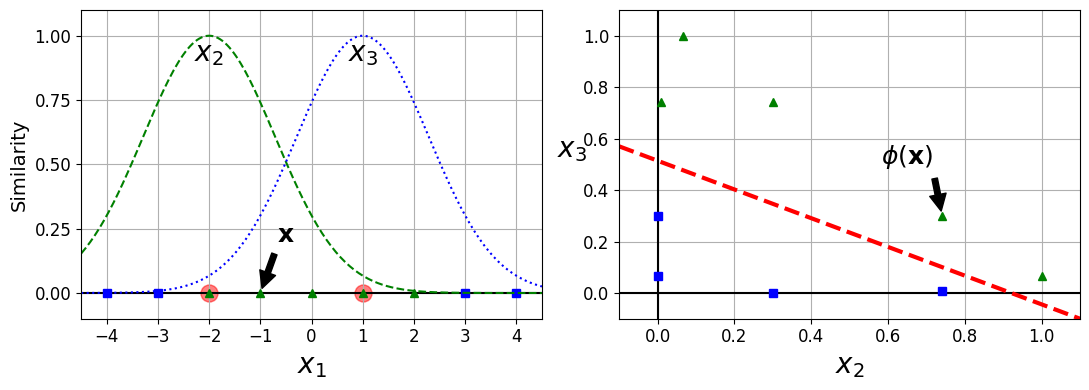

In [44]:
def gaussian_rbf(x, landmark, gamma):
    return np.exp(-gamma * np.linalg.norm(x - landmark, axis=1)**2)

gamma = 0.3

x1s = np.linspace(-4.5, 4.5, 200).reshape(-1, 1)
x2s = gaussian_rbf(x1s, -2, gamma)
x3s = gaussian_rbf(x1s, 1, gamma)

XK = np.c_[gaussian_rbf(X1D, -2, gamma), gaussian_rbf(X1D, 1, gamma)]
yk = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

plt.figure(figsize=(11, 4))

plt.subplot(121)
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.scatter(x=[-2, 1], y=[0, 0], s=150, alpha=0.5, c="red")
plt.plot(X1D[:, 0][yk==0], np.zeros(4), "bs")
plt.plot(X1D[:, 0][yk==1], np.zeros(5), "g^")
plt.plot(x1s, x2s, "g--")
plt.plot(x1s, x3s, "b:")
plt.gca().get_yaxis().set_ticks([0, 0.25, 0.5, 0.75, 1])
plt.xlabel(r"$x_1$", fontsize=20)
plt.ylabel(r"Similarity", fontsize=14)
plt.annotate(r'$\mathbf{x}$',
             xy=(X1D[3, 0], 0),
             xytext=(-0.5, 0.20),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.1),
             fontsize=18,
            )
plt.text(-2, 0.9, "$x_2$", ha="center", fontsize=20)
plt.text(1, 0.9, "$x_3$", ha="center", fontsize=20)
plt.axis([-4.5, 4.5, -0.1, 1.1])

plt.subplot(122)
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(XK[:, 0][yk==0], XK[:, 1][yk==0], "bs")
plt.plot(XK[:, 0][yk==1], XK[:, 1][yk==1], "g^")
plt.xlabel(r"$x_2$", fontsize=20)
plt.ylabel(r"$x_3$  ", fontsize=20, rotation=0)
plt.annotate(r'$\phi\left(\mathbf{x}\right)$',
             xy=(XK[3, 0], XK[3, 1]),
             xytext=(0.65, 0.50),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.1),
             fontsize=18,
            )
plt.plot([-0.1, 1.1], [0.57, -0.1], "r--", linewidth=3)
plt.axis([-0.1, 1.1, -0.1, 1.1])

plt.subplots_adjust(right=1)

save_fig("kernel_method_plot")
plt.show()

#### Evaluación de Kernel RBF y Análisis Sistemático de Hiperparámetros en SVM

Se realiza la cuantificación de similitudes kernel para un punto de ejemplo específico ($x_1$ = 0.0) con respecto a dos puntos de referencia localizados en -2 y 1. Utilizando la función gaussian_rbf previamente definida con parámetro gamma=0.3, se calculan los valores de transformación kernel que representan las coordenadas del punto en el nuevo espacio de características. Los resultados numéricos demuestran cómo un punto unidimensional se proyecta bidimensionalmente mediante medidas de similitud exponencialmente decrecientes con la distancia a cada landmark. Esta transformación ilustra el mecanismo fundamental mediante el cual los kernels implícitamente mapean datos a espacios de mayor dimensionalidad donde las relaciones no lineales pueden volverse linealmente separables.

In [45]:
x1_example = X1D[3, 0]
for landmark in (-2, 1):
    k = gaussian_rbf(np.array([[x1_example]]), np.array([[landmark]]), gamma)
    print("Phi({}, {}) = {}".format(x1_example, landmark, k))

Phi(-1.0, -2) = [0.74081822]
Phi(-1.0, 1) = [0.30119421]


#### Implementación de Clasificador SVM con Kernel RBF

Se configura un pipeline de clasificación que integra estandarización de características con un clasificador SVC utilizando kernel de base radial (RBF). La parametrización específica con gamma=5 y C=0.001 establece un modelo donde la influencia de cada instancia de entrenamiento es localizada (gamma alto) combinada con una regularización fuerte (C bajo). Esta configuración produce un clasificador conservador que prioriza márgenes amplios y generalización sobre ajuste preciso a patrones complejos en los datos. El entrenamiento sobre el conjunto "moons" permite evaluar el comportamiento de kernels RBF en problemas de clasificación con estructura no lineal intrínseca.

In [46]:
rbf_kernel_svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", SVC(kernel="rbf", gamma=5, C=0.001))
    ])
rbf_kernel_svm_clf.fit(X, y)

,steps,"[('scaler', ...), ('svm_clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,0.001
,kernel,'rbf'
,degree,3
,gamma,5


#### Estudio Experimental de Sensibilidad a Hiperparámetros

Se diseña un experimento factorial completo que evalúa el impacto combinado de los hiperparámetros gamma y C en la geometría de las fronteras de decisión. Las cuatro combinaciones examinadas representan escenarios contrastantes: (gamma=0.1, C=0.001) produce el modelo más conservador con fronteras suaves; (gamma=0.1, C=1000) mantiene suavidad pero con márgenes reducidos; (gamma=5, C=0.001) muestra alta complejidad local con regularización fuerte; y (gamma=5, C=1000) representa el modelo más complejo con ajuste máximo a los datos de entrenamiento.

La visualización cuádruple resultante revela patrones sistemáticos en la sensibilidad del modelo a estos hiperparámetros. Valores bajos de gamma generan fronteras de decisión globalmente suaves que capturan la estructura general de los datos, mientras valores altos producen regiones de clasificación fragmentadas que se adaptan a variaciones locales. Paralelamente, valores bajos de C promueven márgenes amplios que ignoran instancias periféricas, mientras valores altos fuerzan ajuste preciso incluso a observaciones potencialmente aberrantes.

Este análisis metodológico proporciona evidencia empírica sobre la criticidad de la selección de hiperparámetros en SVM con kernel RBF, demostrando cómo gamma controla esencialmente la complejidad del modelo y C regula el trade-off entre ajuste y generalización. La interacción observada entre estos parámetros subraya la necesidad de estrategias de optimización sistemática para alcanzar el balance óptimo en aplicaciones prácticas.

Saving figure moons_rbf_svc_plot


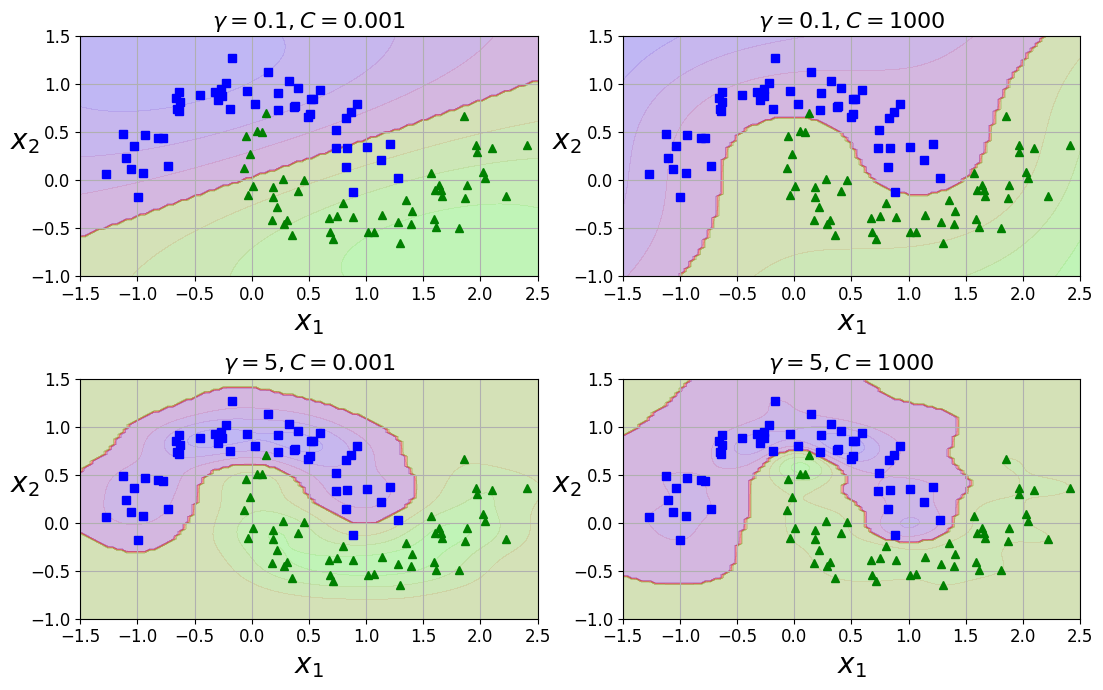

In [47]:
from sklearn.svm import SVC

gamma1, gamma2 = 0.1, 5
C1, C2 = 0.001, 1000
hyperparams = (gamma1, C1), (gamma1, C2), (gamma2, C1), (gamma2, C2)

svm_clfs = []
for gamma, C in hyperparams:
    rbf_kernel_svm_clf = Pipeline([
            ("scaler", StandardScaler()),
            ("svm_clf", SVC(kernel="rbf", gamma=gamma, C=C))
        ])
    rbf_kernel_svm_clf.fit(X, y)
    svm_clfs.append(rbf_kernel_svm_clf)

plt.figure(figsize=(11, 7))

for i, svm_clf in enumerate(svm_clfs):
    plt.subplot(221 + i)
    plot_predictions(svm_clf, [-1.5, 2.5, -1, 1.5])
    plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
    gamma, C = hyperparams[i]
    plt.title(r"$\gamma = {}, C = {}$".format(gamma, C), fontsize=16)

save_fig("moons_rbf_svc_plot")
plt.show()

#### Máquinas de Vectores de Soporte para Regresión

Se genera un conjunto de datos sintético de 50 observaciones con una única variable predictiva distribuida uniformemente en el intervalo [0, 2]. La variable respuesta se construye mediante un modelo lineal subyacente con intercepto 4 y pendiente 3, contaminado con ruido gaussiano estándar para simular condiciones realistas de medición. La transformación ravel() convierte la variable respuesta de formato matricial a vectorial, requisito para la interfaz de scikit-learn. Este conjunto de datos sintético permite evaluar el comportamiento de SVM en contextos de regresión con relaciones lineales conocidas y ruido controlado.

In [48]:
np.random.seed(42)
m = 50
X = 2 * np.random.rand(m, 1)
y = (4 + 3 * X + np.random.randn(m, 1)).ravel()

#### Implementación de Support Vector Regression Lineal

Se instancia y entrena un modelo `LinearSVR` con parámetro épsilon establecido en 1.5, configurando un margen de tolerancia donde errores de predicción inferiores a este umbral no se penalizan en la función de costo. Esta implementación de regresión por vectores de soporte busca encontrar una función lineal que minimice la desviación de las observaciones fuera del tubo épsilon mientras maximiza la planitud de la función de regresión. El entrenamiento sobre los datos sintéticos genera un modelo que aproxima la relación lineal subyacente mientras proporciona robustez frente a observaciones aberrantes mediante el principio de margen máximo adaptado a problemas de regresión.

In [49]:
from sklearn.svm import LinearSVR

svm_reg = LinearSVR(epsilon=1.5, random_state=42)
svm_reg.fit(X, y)

,epsilon,1.5
,tol,0.0001
,C,1.0
,loss,'epsilon_insensitive'
,fit_intercept,True
,intercept_scaling,1.0
,dual,'auto'
,verbose,0
,random_state,42
,max_iter,1000


#### Análisis Comparativo de Sensibilidad al Parámetro Épsilon

Se entrenan dos modelos `LinearSVR` idénticos en arquitectura pero con diferentes valores de épsilon (1.5 y 0.5) para evaluar el impacto de este hiperparámetro en la solución de regresión. La función `find_support_vectors` implementa un mecanismo para identificar vectores soporte en modelos de regresión SVM, definiendo como tales aquellas observaciones cuyos residuos absolutos igualan o exceden el valor épsilon configurado. Esta identificación se realiza comparando las desviaciones entre valores observados y predichos contra el umbral de tolerancia.

El modelo con épsilon=1.5 producirá un tubo de regresión más amplio, incorporando menos observaciones como vectores soporte y generando una solución más robusta a outliers pero potencialmente menos precisa. Contrariamente, el modelo con épsilon=0.5 establecerá un tubo más estrecho, resultando en una función de regresión que se ajusta más estrechamente a los datos de entrenamiento a expensas de mayor sensibilidad a observaciones aberrantes.

La evaluación de un punto específico (`eps_x1 = 1`) mediante predicción con el primer modelo demuestra el comportamiento práctico del algoritmo, mostrando cómo las predicciones se ven influenciadas por la configuración de épsilon y la localización de vectores soporte. Este análisis comparativo ilustra el trade-off fundamental en SVR entre robustez y precisión, donde épsilon actúa como parámetro de control crítico que determina el balance entre tolerancia al error y capacidad de ajuste a patrones finos en los datos.

In [50]:
svm_reg1 = LinearSVR(epsilon=1.5, random_state=42)
svm_reg2 = LinearSVR(epsilon=0.5, random_state=42)
svm_reg1.fit(X, y)
svm_reg2.fit(X, y)

def find_support_vectors(svm_reg, X, y):
    y_pred = svm_reg.predict(X)
    off_margin = (np.abs(y - y_pred) >= svm_reg.epsilon)
    return np.argwhere(off_margin)

svm_reg1.support_ = find_support_vectors(svm_reg1, X, y)
svm_reg2.support_ = find_support_vectors(svm_reg2, X, y)

eps_x1 = 1
eps_y_pred = svm_reg1.predict([[eps_x1]])

#### Visualización de Support Vector Regression

Se define la función `plot_svm_regression` que genera una representación comprehensiva de modelos de regresión por vectores de soporte. La función calcula predicciones sobre una malla de 100 puntos equidistantes en el rango especificado, permitiendo visualizar la función de regresión aprendida como una línea continua. Las fronteras del tubo épsilon se representan mediante líneas discontinuas paralelas a la función de regresión, ubicadas a distancia ±épsilon de la línea central. Los vectores soporte se destacan visualmente con marcadores de color rojo claro (#FFAAAA) y tamaño aumentado, enfatizando su role crítico en la definición de la solución. Las observaciones originales se muestran como puntos azules, proporcionando contexto sobre la distribución de los datos de entrenamiento.

El panel izquierdo presenta la solución de regresión con épsilon=1.5, mostrando un tubo de tolerancia amplio que engloba la mayoría de las observaciones. La función de regresión resultante prioriza suavidad y generalización, mostrando menor sensibilidad a variaciones locales en los datos. Los vectores soporte se limitan predominantemente a observaciones con desviaciones significativas del patrón general, reflejando la filosofía de minimizar el número de instancias que influyen activamente en la solución. La anotación con flechas y texto clarifica visualmente el concepto de épsilon como margen de tolerancia alrededor de la predicción.

El panel derecho ilustra la solución correspondiente a épsilon=0.5, donde el tubo de tolerancia sustancialmente más estrecho fuerza al modelo a ajustarse más estrechamente a las variaciones en los datos. Esta configuración resulta en una función de regresión que captura patrones más finos y una mayor cantidad de vectores soporte, ya que más observaciones caen fuera del estrecho margen de tolerancia. El modelo prioriza precisión en el conjunto de entrenamiento sobre suavidad de la función de regresión.

La visualización comparativa demuestra empíricamente cómo el parámetro épsilon controla fundamentalmente el trade-off entre robustez y precisión en Support Vector Regression. Valores altos de épsilon producen modelos más simples y estables, menos sensibles a ruido y observaciones atípicas, pero potencialmente incapaces de capturar variaciones importantes en los datos. Valores bajos de épsilon generan modelos más complejos que se ajustan estrechamente a los patrones observados, con riesgo de sobreajuste y sensibilidad a anomalías en el conjunto de entrenamiento.

La distancia vertical entre las líneas discontinuas en cada gráfico representa visualmente el margen de error no penalizado, ilustrando cómo épsilon define esencialmente la precisión requerida del modelo. Esta representación gráfica proporciona una comprensión intuitiva de por qué la selección apropiada de épsilon es crítica para el desempeño de SVR en aplicaciones prácticas, donde debe reflejar el nivel inherente de ruido en los datos y los requisitos de precisión del dominio de aplicación específico.

Saving figure svm_regression_plot


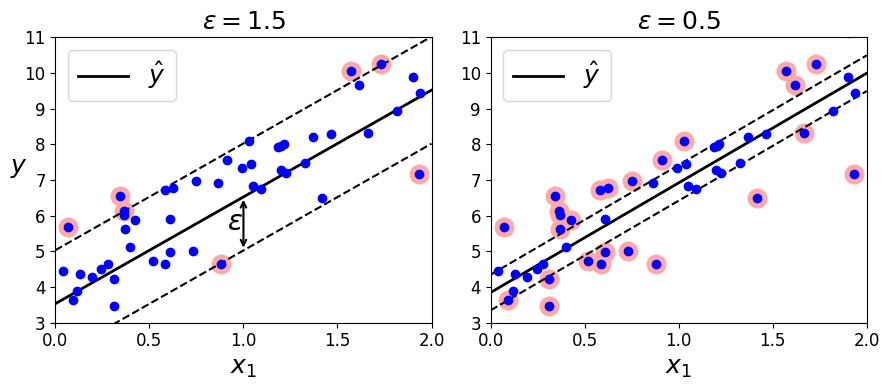

In [51]:
def plot_svm_regression(svm_reg, X, y, axes):
    x1s = np.linspace(axes[0], axes[1], 100).reshape(100, 1)
    y_pred = svm_reg.predict(x1s)
    plt.plot(x1s, y_pred, "k-", linewidth=2, label=r"$\hat{y}$")
    plt.plot(x1s, y_pred + svm_reg.epsilon, "k--")
    plt.plot(x1s, y_pred - svm_reg.epsilon, "k--")
    plt.scatter(X[svm_reg.support_], y[svm_reg.support_], s=180, facecolors='#FFAAAA')
    plt.plot(X, y, "bo")
    plt.xlabel(r"$x_1$", fontsize=18)
    plt.legend(loc="upper left", fontsize=18)
    plt.axis(axes)

plt.figure(figsize=(9, 4))
plt.subplot(121)
plot_svm_regression(svm_reg1, X, y, [0, 2, 3, 11])
plt.title(r"$\epsilon = {}$".format(svm_reg1.epsilon), fontsize=18)
plt.ylabel(r"$y$", fontsize=18, rotation=0)
#plt.plot([eps_x1, eps_x1], [eps_y_pred, eps_y_pred - svm_reg1.epsilon], "k-", linewidth=2)
plt.annotate(
        '', xy=(eps_x1, eps_y_pred), xycoords='data',
        xytext=(eps_x1, eps_y_pred - svm_reg1.epsilon),
        textcoords='data', arrowprops={'arrowstyle': '<->', 'linewidth': 1.5}
    )
plt.text(0.91, 5.6, r"$\epsilon$", fontsize=20)
plt.subplot(122)
plot_svm_regression(svm_reg2, X, y, [0, 2, 3, 11])
plt.title(r"$\epsilon = {}$".format(svm_reg2.epsilon), fontsize=18)
save_fig("svm_regression_plot")
plt.show()

#### Regresión con Máquinas de Vectores de Soporte No Lineales

Se crea un conjunto de datos de 100 observaciones con una variable predictiva distribuida uniformemente en el intervalo [-1, 1]. La variable respuesta se genera mediante un modelo polinomial cuadrático subyacente con parámetros específicos: $0.5x^{2}+0.1x+0.2$ contaminado con ruido gaussiano de escala reducida (desviación estándar 0.1). La transformación `ravel()` asegura la compatibilidad dimensional con los algoritmos de scikit-learn. Este diseño experimental crea un escenario de regresión no lineal controlado que permite evaluar la capacidad de los modelos SVM para capturar relaciones complejas entre variables, simulando condiciones típicas encontradas en aplicaciones con patrones curvilíneos y ruido de medición.

In [52]:
np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1) - 1
y = (0.2 + 0.1 * X + 0.5 * X**2 + np.random.randn(m, 1)/10).ravel()

#### Implementación de Support Vector Regression con Kernel Polinomial

Se instancia y entrena un modelo SVR con kernel polinomial de segundo grado, configurado con parámetro de regularización C=100 y épsilon=0.1. Esta parametrización específica establece un modelo de alta complejidad que busca capturar la relación cuadrática subyacente en los datos mientras mantiene un margen de tolerancia moderado para errores de predicción. El kernel polinomial de grado 2 permite al modelo operar en un espacio de características expandido donde la relación no lineal original se transforma en linealmente modelable, sin requerir transformación explícita de las variables de entrada. El valor elevado de C indica baja tolerancia a violaciones del tubo épsilon, forzando un ajuste más estrecho a los datos de entrenamiento.

In [53]:
from sklearn.svm import SVR

svm_poly_reg = SVR(kernel="poly", degree=2, C=100, epsilon=0.1)
svm_poly_reg.fit(X, y)

,kernel,'poly'
,degree,2
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,100
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


#### Estudio Comparativo de Intensidades de Regularización en SVR No Lineal

Se entrenan dos modelos SVR idénticos en estructura de kernel (polinomial grado 2) y parámetro épsilon (0.1), pero con valores de regularización C radicalmente diferentes: 100 versus 0.01. Esta configuración experimental permite aislar y examinar el efecto del parámetro C en la solución de regresión para problemas no lineales. El modelo con C=100 representa un enfoque de bajo sesgo que prioriza el ajuste preciso a los patrones observados en los datos de entrenamiento, potencialmente capturando tanto la señal subyacente como componentes de ruido. Contrariamente, el modelo con C=0.01 implementa una regularización fuerte que promueve soluciones más simples y suaves, sacrificando precisión de entrenamiento en favor de potencial mejora en generalización.

La comparación sistemática de estos modelos sobre el conjunto de datos cuadrático sintético proporciona insights valiosos sobre la interacción entre complejidad del kernel y intensidad de regularización en contextos de regresión no lineal. El análisis visual posterior de las soluciones resultantes permite evaluar cómo diferentes balances entre ajuste y generalización se manifiestan en la geometría de las funciones de regresión aprendidas, particularmente en la capacidad de capturar la curvatura cuadrática genuina mientras se mitiga el sobreajuste a fluctuaciones aleatorias en los datos.

In [54]:
from sklearn.svm import SVR

svm_poly_reg1 = SVR(kernel="poly", degree=2, C=100, epsilon=0.1)
svm_poly_reg2 = SVR(kernel="poly", degree=2, C=0.01, epsilon=0.1)
svm_poly_reg1.fit(X, y)
svm_poly_reg2.fit(X, y)

,kernel,'poly'
,degree,2
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,0.01
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


#### Análisis Visual Comparativo de Modelos SVR con Kernel Polinomial

La figura presenta una comparación side-by-side de dos configuraciones de Support Vector Regression con kernel polinomial, destacando el impacto del parámetro de regularización C en la geometría de la función de regresión aprendida. Ambos modelos comparten idéntica estructura de kernel polinomial de segundo grado y valor de épsilon (0.1), permitiendo aislar el efecto específico del hiperparámetro C en la solución final.

El panel izquierdo muestra la solución correspondiente al modelo con regularización mínima (C=100), donde la función de regresión exhibe una curvatura pronunciada que se ajusta estrechamente a las variaciones locales en los datos. Esta configuración produce un tubo de épsilon relativamente estrecho que contiene la mayoría de las observaciones, con vectores soporte concentrados principalmente en regiones de alta curvatura y puntos aberrantes. La solución demuestra la capacidad del kernel polinomial para capturar la relación cuadrática subyacente en los datos, aunque con potencial riesgo de sobreajuste a fluctuaciones de ruido específicas del conjunto de entrenamiento.

El panel derecho ilustra el comportamiento del modelo con regularización fuerte (C=0.01), donde la función de regresión resultante presenta una curvatura más suave y generalizada. El tubo de épsilon, aunque mantiene el mismo ancho nominal, contiene proporcionalmente más observaciones debido a la naturaleza menos compleja de la función de regresión. Los vectores soporte se distribuyen más uniformemente a lo largo del dominio, reflejando la influencia más equilibrada de las observaciones en la solución final. Esta configuración prioriza la suavidad de la función de regresión sobre el ajuste preciso a variaciones locales, potencialmente mejorando la generalización a nuevos datos.

La comparación visual evidencia el trade-off fundamental controlado por el parámetro C en SVR con kernels no lineales. Valores elevados de C permiten al modelo capturar patrones complejos y variaciones finas en los datos, produciendo funciones de regresión con alta fidelidad al conjunto de entrenamiento. Valores reducidos de C promueven soluciones más simples y suaves que, aunque potencialmente menos precisas en los datos de entrenamiento, pueden generalizar mejor a observaciones no vistas.

La preservación del mismo valor de épsilon en ambos modelos asegura que las diferencias observadas se atribuyan exclusivamente al parámetro de regularización, demostrando cómo C actúa como mecanismo de control de complejidad independientemente del ancho del tubo de tolerancia. Esta visualización proporciona una comprensión intuitiva de cómo la selección apropiada de hiperparámetros en SVR con kernels no lineales es crítica para alcanzar el balance óptimo entre capacidad de modelado y generalización en problemas de regresión con relaciones complejas subyacentes.

Saving figure svm_with_polynomial_kernel_plot


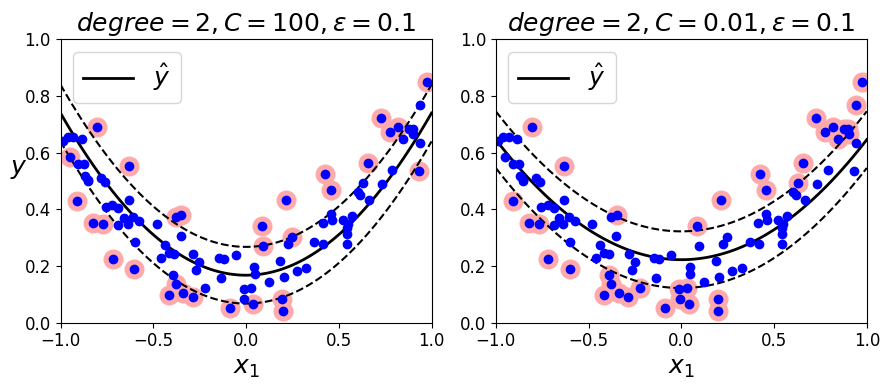

In [55]:
plt.figure(figsize=(9, 4))
plt.subplot(121)
plot_svm_regression(svm_poly_reg1, X, y, [-1, 1, 0, 1])
plt.title(r"$degree={}, C={}, \epsilon = {}$".format(svm_poly_reg1.degree, svm_poly_reg1.C, svm_poly_reg1.epsilon), fontsize=18)
plt.ylabel(r"$y$", fontsize=18, rotation=0)
plt.subplot(122)
plot_svm_regression(svm_poly_reg2, X, y, [-1, 1, 0, 1])
plt.title(r"$degree={}, C={}, \epsilon = {}$".format(svm_poly_reg2.degree, svm_poly_reg2.C, svm_poly_reg2.epsilon), fontsize=18)
save_fig("svm_with_polynomial_kernel_plot")
plt.show()

#### Análisis Tridimensional de la Función de Decisión en Máquinas de Vectores de Soporte

Se utiliza el conjunto de datos Iris para establecer un problema de clasificación binaria centrado en la identificación de la especie Iris-Virginica. Se seleccionan específicamente dos características morfológicas: longitud del pétalo y ancho del pétalo, reconocidas en la literatura botánica como altamente discriminativas para la diferenciación de especies. La variable objetivo se transforma en una representación binaria donde el valor 1.0 indica pertenencia a Iris-Virginica y 0.0 representa las demás especies (Setosa y Versicolor). Esta configuración permite analizar el mecanismo de clasificación SVM en un contexto bidimensional simplificado mientras se mantiene relevancia biológica.

In [56]:
iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = (iris["target"] == 2).astype(np.float64)  # Iris-Virginica

#### Implementación de Visualización Tridimensional de la Función de Decisión

Se desarrolla la función `plot_3D_decision_function` que genera una representación tridimensional comprehensiva del mecanismo de clasificación SVM. La función opera en múltiples capas visuales:

Primero se crea una malla bidimensional en el espacio de características original (longitud y ancho del pétalo) y se evalúa la función de decisión lineal $h = w^{t}*x + b$ en cada punto de esta malla. Esta evaluación genera una superficie tridimensional donde la altura representa el valor de la función de decisión, proporcionando una visualización intuitiva de cómo el modelo asigna scores de clasificación a diferentes combinaciones de características.

Luego, se trazan tres líneas fundamentales en el plano base ($z=0$):

- Límite de decisión ($h=0$): Representa el hiperplano de separación donde el modelo es indiferente entre clases
- Límites del margen ($h=±1$): Demarcan el corredor de margen máximo donde se ubican los vectores soporte

Los puntos de datos se proyectan en el plano base ($z=0$) con codificación morfológica (triángulos verdes para Virginica, cuadrados azules para no-Virginica), mientras la superficie de alambre de la función de decisión muestra la variación continua de los scores de clasificación. La relación entre el vector de pesos $w$ y el margen $m = \frac{1}{||w||}$ se manifiesta visualmente en la pendiente y orientación de la superficie.

La visualización tridimensional revela la esencia geométrica de las SVM: la búsqueda del hiperplano que maximiza la distancia perpendicular entre las observaciones más cercanas de clases opuestas. La superficie inclinada muestra cómo la confianza de clasificación aumenta monotónicamente con la distancia al hiperplano de decisión, mientras los límites paralelos $h=

La visualización tridimensional revela la esencia geométrica de las SVM: la búsqueda del hiperplano que maximiza la distancia perpendicular entre las observaciones más cercanas de clases opuestas. La superficie inclinada muestra cómo la confianza de clasificación aumenta monotónicamente con la distancia al hiperplano de decisión, mientras los límites paralelos $h=±1$ definen el corredor de separación óptimo.

La proyección de los datos en el plano base junto con la superficie elevada de la función de decisión permite apreciar simultáneamente la distribución empírica de las observaciones y el modelo teórico aprendido, facilitando la comprensión de cómo las SVM transforman problemas de clasificación en tareas de regresión sobre scores de decisión. Esta representación proporciona insights fundamentales sobre la interpretación geométrica de los parámetros del modelo ($w$ y $b$) y su relación con el concepto de margen de clasificación.

TypeError: The first argument to axis() must be an iterable of the form [xmin, xmax, ymin, ymax, zmin, zmax]

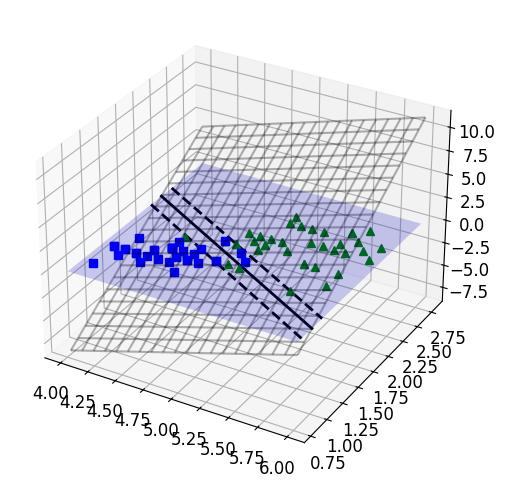

In [57]:
from mpl_toolkits.mplot3d import Axes3D

def plot_3D_decision_function(ax, w, b, x1_lim=[4, 6], x2_lim=[0.8, 2.8]):
    x1_in_bounds = (X[:, 0] > x1_lim[0]) & (X[:, 0] < x1_lim[1])
    X_crop = X[x1_in_bounds]
    y_crop = y[x1_in_bounds]
    x1s = np.linspace(x1_lim[0], x1_lim[1], 20)
    x2s = np.linspace(x2_lim[0], x2_lim[1], 20)
    x1, x2 = np.meshgrid(x1s, x2s)
    xs = np.c_[x1.ravel(), x2.ravel()]
    df = (xs.dot(w) + b).reshape(x1.shape)
    m = 1 / np.linalg.norm(w)
    boundary_x2s = -x1s*(w[0]/w[1])-b/w[1]
    margin_x2s_1 = -x1s*(w[0]/w[1])-(b-1)/w[1]
    margin_x2s_2 = -x1s*(w[0]/w[1])-(b+1)/w[1]
    ax.plot_surface(x1s, x2, np.zeros_like(x1),
                    color="b", alpha=0.2, cstride=100, rstride=100)
    ax.plot(x1s, boundary_x2s, 0, "k-", linewidth=2, label=r"$h=0$")
    ax.plot(x1s, margin_x2s_1, 0, "k--", linewidth=2, label=r"$h=\pm 1$")
    ax.plot(x1s, margin_x2s_2, 0, "k--", linewidth=2)
    ax.plot(X_crop[:, 0][y_crop==1], X_crop[:, 1][y_crop==1], 0, "g^")
    ax.plot_wireframe(x1, x2, df, alpha=0.3, color="k")
    ax.plot(X_crop[:, 0][y_crop==0], X_crop[:, 1][y_crop==0], 0, "bs")
    ax.axis(x1_lim + x2_lim)
    ax.text(4.5, 2.5, 3.8, "Decision function $h$", fontsize=15)
    ax.set_xlabel(r"Petal length", fontsize=15)
    ax.set_ylabel(r"Petal width", fontsize=15)
    ax.set_zlabel(r"$h = \mathbf{w}^t \cdot \mathbf{x} + b$", fontsize=18)
    ax.legend(loc="upper left", fontsize=16)

fig = plt.figure(figsize=(11, 6))
ax1 = fig.add_subplot(111, projection='3d')
plot_3D_decision_function(ax1, w=svm_clf2.coef_[0], b=svm_clf2.intercept_[0])

save_fig("iris_3D_plot")
plt.show()

#### Análisis Bidimensional de la Función de Decisión SVM: Relación entre Peso y Margen

Se define la función `plot_2D_decision_function` que genera una representación bidimensional simplificada del mecanismo de clasificación SVM para el caso de una única característica. La función traza la relación lineal $y = w_1*x_1 + b$ que constituye el núcleo de la función de decisión en clasificación SVM. El parámetro $w_1$ representa el peso asociado a la característica $x_1$, mientras $b$ denota el término de sesgo que desplaza la función verticalmente.

La visualización incorpora múltiples componentes que ilustran conceptos fundamentales de SVM:

- **Línea de decisión principal**: Representa la función $w_1*x_1 + b$ que determina el score de clasificación
- **Límites de margen**: Líneas horizontales en $y=1$ e $y=-1$ que definen el corredor de tolerancia
- **Ejes de referencia**: Líneas vertical y horizontal en cero para establecer el sistema de coordenadas
- **Indicadores de margen**: Líneas discontinuas verticales en $x_1=m$ y $x_1=-m$ que marcan la proyección del margen
- **Representación del vector peso**: Segmento entre $m$ y $-m$ en el eje horizontal que visualiza la magnitud del margen

El panel izquierdo muestra el caso donde $w_1=1$ y $b=0$, resultando en una función de decisión con pendiente unitaria. La distancia del margen $m = \frac{1}{||w||}=1$ se manifiesta como la separación horizontal entre las líneas discontinuas verticales. Esta configuración produce un margen moderado donde la función de decisión alcanza valores de $±1$ en puntos separados por dos unidades en el eje $x_1$. 

El panel derecho ilustra el caso con $w_1=0.5$ y $b=0$, donde la pendiente más suave de la función de decisión resulta en un margen significativamente ampliado ($m=2$). La distancia horizontal entre los límites de margen se duplica comparada con el caso anterior, demostrando la relación inversa entre la magnitud del vector de pesos y el tamaño del margen de clasificación.

Saving figure small_w_large_margin_plot


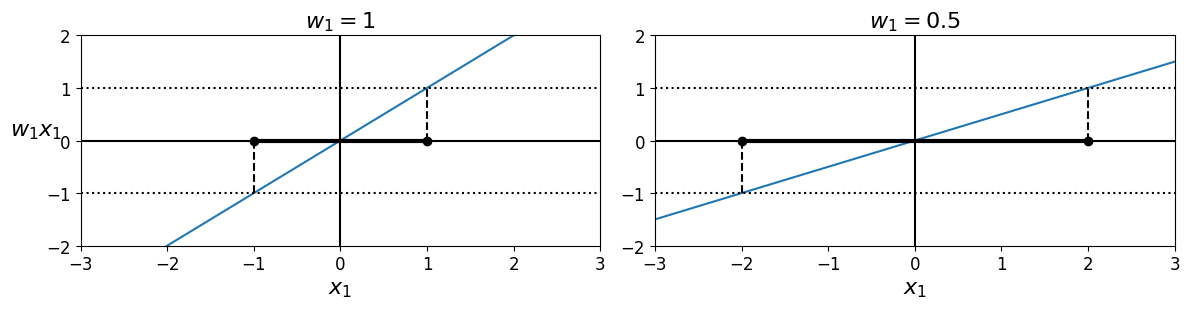

In [58]:
def plot_2D_decision_function(w, b, ylabel=True, x1_lim=[-3, 3]):
    x1 = np.linspace(x1_lim[0], x1_lim[1], 200)
    y = w * x1 + b
    m = 1 / w

    plt.plot(x1, y)
    plt.plot(x1_lim, [1, 1], "k:")
    plt.plot(x1_lim, [-1, -1], "k:")
    plt.axhline(y=0, color='k')
    plt.axvline(x=0, color='k')
    plt.plot([m, m], [0, 1], "k--")
    plt.plot([-m, -m], [0, -1], "k--")
    plt.plot([-m, m], [0, 0], "k-o", linewidth=3)
    plt.axis(x1_lim + [-2, 2])
    plt.xlabel(r"$x_1$", fontsize=16)
    if ylabel:
        plt.ylabel(r"$w_1 x_1$  ", rotation=0, fontsize=16)
    plt.title(r"$w_1 = {}$".format(w), fontsize=16)

plt.figure(figsize=(12, 3.2))
plt.subplot(121)
plot_2D_decision_function(1, 0)
plt.subplot(122)
plot_2D_decision_function(0.5, 0, ylabel=False)
save_fig("small_w_large_margin_plot")
plt.show()

#### Implementación de Clasificación SVM y Visualización de la Función de Pérdida Hinge

Se implementa un clasificador SVM con kernel lineal para el problema de identificación de la especie Iris-Virginica dentro del conjunto de datos Iris. La selección de características se limita a las dimensiones del pétalo (longitud y ancho), reconocidas como altamente discriminativas para la distinción de especies. La variable objetivo se transforma en una representación binaria donde 1.0 identifica especímenes de Iris-Virginica y 0.0 agrupa las especies restantes.

El modelo se configura con parámetro de regularización C=1, estableciendo un balance moderado entre maximización del margen y tolerancia a violaciones del mismo. Tras el proceso de entrenamiento, el clasificador se utiliza para predecir la clasificación de un nuevo espécimen con longitud de pétalo 5.3 cm y ancho de pétalo 1.3 cm, demostrando el flujo operativo estándar de inferencia en problemas de clasificación con SVM.

In [59]:
from sklearn.svm import SVC
from sklearn import datasets

iris = datasets.load_iris()
X = iris["data"][:, (2, 3)] # petal length, petal width
y = (iris["target"] == 2).astype(np.float64) # Iris-Virginica

svm_clf = SVC(kernel="linear", C=1)
svm_clf.fit(X, y)
svm_clf.predict([[5.3, 1.3]])

array([1.])

#### Análisis Matemático de la Función de Pérdida Hinge

Se implementa una visualización de la función de pérdida hinge, componente fundamental en la formulación de Máquinas de Vectores de Soporte para clasificación. La función se define como $max(0, 1 - t)$, donde t representa el producto entre la etiqueta verdadera (en formato ±1) y el valor de la función de decisión. Esta formulación penaliza aquellas observaciones que no solo se clasifican incorrectamente, sino también aquellas correctamente clasificadas que se encuentran dentro del margen de confianza.

La gráfica resultante muestra el comportamiento característico de la pérdida hinge: valores cero para $t ≥ 1$, indicando que observaciones correctamente clasificadas con margen suficiente no contribuyen a la pérdida; y un incremento lineal para $t < 1$, donde la magnitud de la penalización aumenta proporcionalmente a la violación del margen. El punto de transición en $t = 1$ marca el límite donde las observaciones dejan de considerarse dentro del margen de confianza.

Saving figure hinge_plot


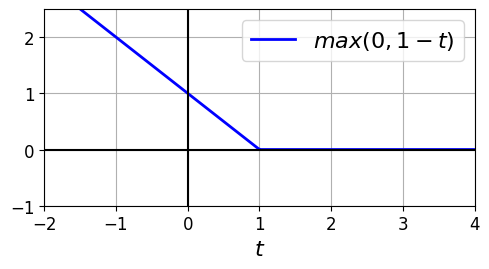

In [60]:
t = np.linspace(-2, 4, 200)
h = np.where(1 - t < 0, 0, 1 - t)  # max(0, 1-t)

plt.figure(figsize=(5,2.8))
plt.plot(t, h, "b-", linewidth=2, label="$max(0, 1 - t)$")
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.yticks(np.arange(-1, 2.5, 1))
plt.xlabel("$t$", fontsize=16)
plt.axis([-2, 4, -1, 2.5])
plt.legend(loc="upper right", fontsize=16)
save_fig("hinge_plot")
plt.show()

#### Generación de Conjuntos de Datos Complejos y Análisis de Sensibilidad de Tolerancia en Optimización SVM y Caracterización de Conjunto de Datos "Moons" a Gran Escala

Se genera un conjunto de datos sintético de mayor escala utilizando la función make_moons con 1000 observaciones y un nivel de ruido de 0.4, creando un problema de clasificación binaria con estructura no lineal compleja y solapamiento significativo entre clases. La visualización resultante muestra la disposición característica de dos formaciones semilunares entrelazadas, donde los patrones de clase 0 (cuadrados azules) y clase 1 (triángulos verdes) se distribuyen en configuraciones curvilíneas con variabilidad sustancial introducida por el parámetro de ruido. Este conjunto de datos de mayor escala y complejidad proporciona un escenario más desafiante para evaluar el rendimiento de algoritmos de clasificación en condiciones que simulan problemas del mundo real con relaciones no lineales y cierto grado de superposición entre categorías.

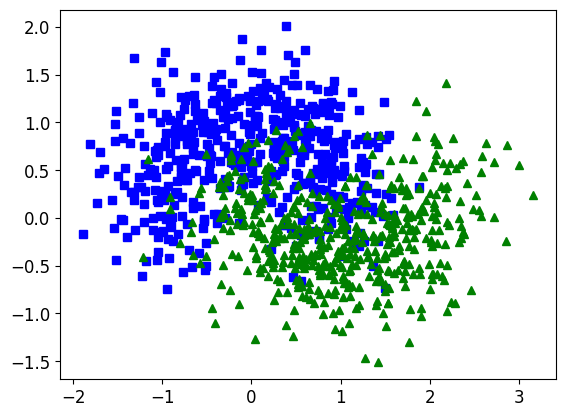

In [61]:
X, y = make_moons(n_samples=1000, noise=0.4, random_state=42)
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")

#### Análisis Sistemático del Impacto de la Tolerancia en el Desempeño Computacional de SVM

Se implementa un experimento controlado para cuantificar la relación entre el parámetro de tolerancia (tol) en algoritmos SVM y el tiempo requerido para la convergencia del proceso de optimización. El parámetro de tolerancia define el criterio de parada para el algoritmo de optimización, estableciendo el umbral de mejora mínima requerida en la función objetivo para continuar las iteraciones.

El estudio varía sistemáticamente el valor de tolerancia a través de diez iteraciones, reduciendo el valor en un orden de magnitud en cada paso (de $0.1$ a $0.1^{10}$). Para cada configuración de tolerancia, se instancia y entrena un clasificador SVM con kernel polinomial de grado 3, parámetro gamma=3 y C=10, registrando el tiempo de ejecución del método `fit()`. La configuración `verbose=1` habilita salidas detalladas durante el entrenamiento, proporcionando información adicional sobre el proceso de optimización.

Los tiempos de ejecución registrados se visualizan mediante un gráfico semilogarítmico que relaciona los valores de tolerancia (eje x logarítmico) con los tiempos de computación (eje y lineal). Esta representación permite identificar patrones en la relación entre precisión de optimización y costo computacional, típicamente mostrando que valores de tolerancia más estrictos (menores) requieren tiempos de entrenamiento sustancialmente mayores debido al aumento en el número de iteraciones necesarias para alcanzar la convergencia.

Este análisis proporciona insights cuantitativos sobre las compensaciones prácticas en la selección de hiperparámetros de SVM, donde valores de tolerancia muy bajos pueden ofrecer soluciones más precisas pero a costos computacionales prohibitivos en aplicaciones a gran escala o tiempo-real. La comprensión de esta relación es esencial para tomar decisiones informadas sobre la configuración de modelos en problemas prácticos donde los recursos computacionales son un factor limitante.

[LibSVM]......................................
*.......................
*..............................................................
*...................................*.......................................................*
optimization finished, #iter = 212105
obj = -4447.997680, rho = 0.075931
nSV = 449, nBSV = 441
0 0.1 0.2675302028656006
[LibSVM]Total nSV = 449
................................................*..........................................................*..............*..............................................................*..................................................................*...........*
optimization finished, #iter = 258151
1 0.01 0.2860989570617676
obj = -4448.479655, rho = 0.058653
nSV = 446, nBSV = 441
Total nSV = 446
[LibSVM]...................................................*......*............................................................*..............................................................................*................

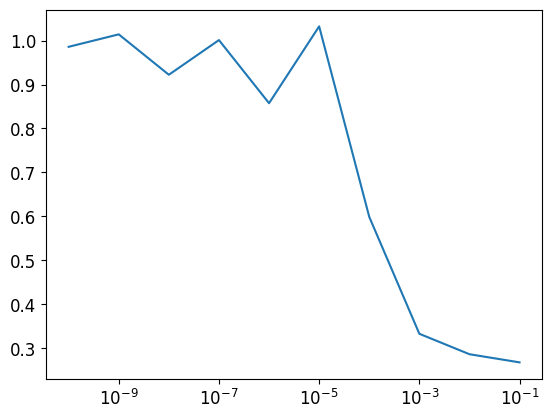

In [62]:
import time

tol = 0.1
tols = []
times = []
for i in range(10):
    svm_clf = SVC(kernel="poly", gamma=3, C=10, tol=tol, verbose=1)
    t1 = time.time()
    svm_clf.fit(X, y)
    t2 = time.time()
    times.append(t2-t1)
    tols.append(tol)
    print(i, tol, t2-t1)
    tol /= 10
plt.semilogx(tols, times)

#### Implementación de Clasificador SVM Lineal Personalizado y Análisis de Convergencia

Se prepara un conjunto de datos para el problema de clasificación de Iris-Virginica utilizando las características de longitud y ancho del pétalo. La variable objetivo se transforma en una representación binaria donde 1.0 identifica la especie Iris-Virginica y 0.0 representa las demás especies. La operación `reshape(-1, 1)` asegura que la variable objetivo mantenga formato matricial bidimensional, requisito para la implementación personalizada del clasificador SVM que sigue. Esta configuración establece las bases para un problema de clasificación binaria con dos características predictoras, permitiendo la evaluación del algoritmo personalizado en un contexto controlado y biológicamente significativo.

In [63]:
# Training set
X = iris["data"][:, (2, 3)] # petal length, petal width
y = (iris["target"] == 2).astype(np.float64).reshape(-1, 1) # Iris-Virginica

#### Implementación de Clasificador SVM Lineal mediante Descenso de Gradiente

Se desarrolla una implementación personalizada de Máquina de Vectores de Soporte lineal mediante la clase `MyLinearSVC`, que extiende `BaseEstimator` de scikit-learn para compatibilidad con el ecosistema de la biblioteca. La implementación utiliza optimización por descenso de gradiente con tasa de aprendizaje adaptativa para resolver el problema de optimización SVM con pérdida hinge.

El algoritmo implementa la formulación primal de SVM con regularización L2, minimizando la función objetivo que combina el término de margen máximo con penalización por violaciones mediante el parámetro C. La inicialización aleatoria de pesos y sesgo asegura un punto de partida no determinista, controlable mediante el parámetro `random_state`.

El proceso de entrenamiento emplea una estrategia de aprendizaje con decaimiento de tasa de aprendizaje, donde la tasa η disminuye conforme avanza el entrenamiento según la relación $η = \frac{η_₀}{época + η_d}$. Esta aproximación permite pasos de optimización agresivos inicialmente que se refinan progresivamente para converger a una solución estable.

En cada época, el algoritmo identifica vectores soporte como aquellas observaciones que violan el margen ($X_t.dot(w) + t * b < 1$). El cálculo de gradientes considera exclusivamente estos vectores soporte, implementando efectivamente una variante de descenso de gradiente por lotes que focaliza recursos computacionales en observaciones críticas para la definición del margen.

La clase implementa `decision_function` para calcular scores de clasificación continuos y predict para generar predicciones binarias basadas en el signo de la función de decisión. La instanciación y entrenamiento con parámetros específicos (C=2, 60000 épocas) demuestra la aplicabilidad práctica del algoritmo, seguida de predicciones de ejemplo que validan el funcionamiento del modelo entrenado.

In [64]:
from sklearn.base import BaseEstimator

class MyLinearSVC(BaseEstimator):
    def __init__(self, C=1, eta0=1, eta_d=10000, n_epochs=1000, random_state=None):
        self.C = C
        self.eta0 = eta0
        self.n_epochs = n_epochs
        self.random_state = random_state
        self.eta_d = eta_d

    def eta(self, epoch):
        return self.eta0 / (epoch + self.eta_d)

    def fit(self, X, y):
        # Random initialization
        if self.random_state:
            np.random.seed(self.random_state)
        w = np.random.randn(X.shape[1], 1) # n feature weights
        b = 0

        m = len(X)
        t = y * 2 - 1  # -1 if t==0, +1 if t==1
        X_t = X * t
        self.Js=[]

        # Training
        for epoch in range(self.n_epochs):
            support_vectors_idx = (X_t.dot(w) + t * b < 1).ravel()
            X_t_sv = X_t[support_vectors_idx]
            t_sv = t[support_vectors_idx]

            J = 1/2 * np.sum(w * w) + self.C * (np.sum(1 - X_t_sv.dot(w)) - b * np.sum(t_sv))
            self.Js.append(J)

            w_gradient_vector = w - self.C * np.sum(X_t_sv, axis=0).reshape(-1, 1)
            b_derivative = -C * np.sum(t_sv)

            w = w - self.eta(epoch) * w_gradient_vector
            b = b - self.eta(epoch) * b_derivative


        self.intercept_ = np.array([b])
        self.coef_ = np.array([w])
        support_vectors_idx = (X_t.dot(w) + b < 1).ravel()
        self.support_vectors_ = X[support_vectors_idx]
        return self

    def decision_function(self, X):
        return X.dot(self.coef_[0]) + self.intercept_[0]

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(np.float64)

C=2
svm_clf = MyLinearSVC(C=C, eta0 = 10, eta_d = 1000, n_epochs=60000, random_state=2)
svm_clf.fit(X, y)
svm_clf.predict(np.array([[5, 2], [4, 1]]))

array([[1.],
       [0.]])

#### Análisis de Convergencia del Algoritmo de Optimización

Se visualiza la evolución de la función de costo J a lo largo del proceso de entrenamiento, graficando los valores almacenados en Js para cada época. Esta visualización permite monitorizar el comportamiento de convergencia del algoritmo de descenso de gradiente personalizado, mostrando cómo la función objetivo decrece monotónicamente durante las iteraciones iniciales antes de estabilizarse cerca de un mínimo local.

El gráfico resultante proporciona insights sobre la eficacia de la estrategia de tasa de aprendizaje adaptativa y la estabilidad numérica de la implementación. La escala del eje Y ([0, 100]) enfatiza la magnitud de la reducción del costo durante las primeras épocas, mientras la persistencia de valores no nulos en épocas avanzadas refleja la naturaleza aproximada de la solución obtenida mediante métodos de descenso de gradiente en problemas de optimización convexa pero no suave como SVM con pérdida hinge.

Esta implementación educativa demuestra los principios fundamentales subyacentes a los algoritmos SVM comerciales, destacando los compromisos entre precisión numérica, eficiencia computacional y complejidad de implementación en métodos de optimización para machine learning.

(np.float64(0.0), np.float64(60000.0), np.float64(0.0), np.float64(100.0))

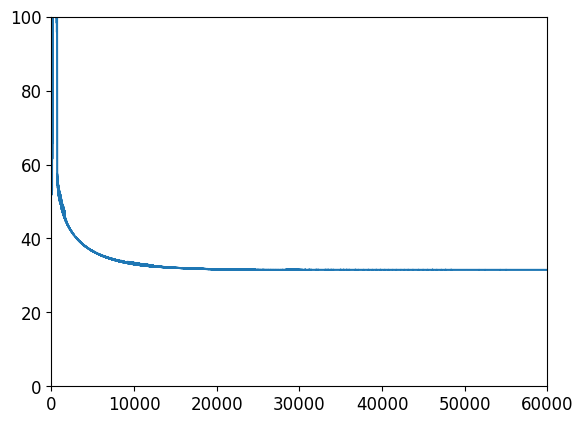

In [65]:
plt.plot(range(svm_clf.n_epochs), svm_clf.Js)
plt.axis([0, svm_clf.n_epochs, 0, 100])

#### Análisis Comparativo de Parámetros y Desempeño Visual entre Implementaciones SVM

Se examinan los parámetros aprendidos por la implementación personalizada `MyLinearSVC`, específicamente el término de intercepto (`intercept_`) y el vector de coeficientes (`coef_`). Estos parámetros representan la solución final del problema de optimización, definiendo matemáticamente el hiperplano de decisión en el espacio de características. El intercepto corresponde al término de sesgo $b$ en la ecuación $w*x+b=0$, mientras los coeficientes representan el vector de pesos $w$ que determina la orientación y pendiente del hiperplano. La inspección de estos valores permite verificar la convergencia del algoritmo de optimización personalizado y proporciona una referencia cuantitativa para comparaciones con implementaciones estandarizadas.

In [66]:
print(svm_clf.intercept_, svm_clf.coef_)

[-15.56761653] [[[2.28120287]
  [2.71621742]]]


#### Entrenamiento y Análisis de Modelo SVM Estándar de scikit-learn

Se instancia y entrena un clasificador SVC con kernel lineal y el mismo valor de parámetro de regularización (C=2) utilizado en la implementación personalizada. La conversión de la variable objetivo a formato unidimensional mediante `ravel()` asegura compatibilidad con la interfaz de scikit-learn. La extracción de parámetros equivalentes (intercepto y coeficientes) del modelo estandarizado permite una comparación directa con la solución obtenida por el algoritmo personalizado. Esta comparación cuantitativa valida la corrección de la implementación personalizada y revela diferencias potenciales atribuibles a variaciones en los algoritmos de optimización, criterios de convergencia o inicialización de parámetros.

In [67]:
svm_clf2 = SVC(kernel="linear", C=C)
svm_clf2.fit(X, y.ravel())
print(svm_clf2.intercept_, svm_clf2.coef_)

[-15.51721253] [[2.27128546 2.71287145]]


#### Evaluación Visual Comparativa de Fronteras de Decisión

Se genera una visualización comparativa side-by-side de las fronteras de decisión producidas por ambos modelos. Ambos subplots utilizan idénticas escalas de ejes y codificación visual de datos (triángulos verdes para Iris-Virginica, cuadrados azules para otras especies), permitiendo una comparación directa e inequívoca de las soluciones obtenidas.

El panel izquierdo muestra la frontera de decisión del clasificador MyLinearSVC, revelando la geometría del hiperplano resultante del algoritmo de descenso de gradiente personalizado. La posición y orientación de la frontera reflejan los parámetros extraídos previamente, demostrando visualmente cómo el modelo separa las clases en el espacio de características de longitud y ancho del pétalo.

El panel derecho presenta la solución del clasificador SVC de scikit-learn, mostrando la frontera de decisión obtenida mediante algoritmos de optimización especializados. Las diferencias sutiles en la posición, orientación o márgenes entre ambas fronteras pueden atribuirse a factores como la precisión numérica, criterios de parada, o el manejo de observaciones en el margen.

Esta evaluación visual dual proporciona una validación cualitativa del algoritmo personalizado, donde la similitud entre ambas fronteras sugiere corrección en la implementación, mientras las diferencias resaltan los efectos de distintas estrategias de optimización. La comparación también ilustra cómo diferentes implementaciones del mismo principio teórico (máximo margen) pueden producir soluciones prácticamente equivalentes pero no idénticas, particularmente en problemas con múltiples soluciones óptimas o near-óptimas. La restricción del área visual al rango morfológico relevante [4, 6] en longitud y [0.8, 2.8] en ancho del pétalo enfoca el análisis en la región donde reside el poder discriminativo real del modelo.

(np.float64(4.0), np.float64(6.0), np.float64(0.8), np.float64(2.8))

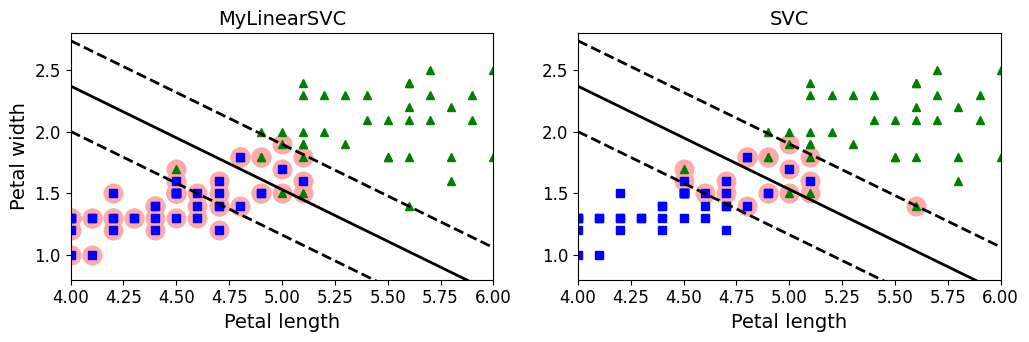

In [68]:
yr = y.ravel()
plt.figure(figsize=(12,3.2))
plt.subplot(121)
plt.plot(X[:, 0][yr==1], X[:, 1][yr==1], "g^", label="Iris-Virginica")
plt.plot(X[:, 0][yr==0], X[:, 1][yr==0], "bs", label="Not Iris-Virginica")
plot_svc_decision_boundary(svm_clf, 4, 6)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.title("MyLinearSVC", fontsize=14)
plt.axis([4, 6, 0.8, 2.8])

plt.subplot(122)
plt.plot(X[:, 0][yr==1], X[:, 1][yr==1], "g^")
plt.plot(X[:, 0][yr==0], X[:, 1][yr==0], "bs")
plot_svc_decision_boundary(svm_clf2, 4, 6)
plt.xlabel("Petal length", fontsize=14)
plt.title("SVC", fontsize=14)
plt.axis([4, 6, 0.8, 2.8])

#### Implementación de SVM Lineal mediante Descenso de Gradiente Estocástico y Análisis de Vectores Soporte

Se implementa un clasificador de Descenso de Gradiente Estocástico (SGD) configurado con función de pérdida hinge, equivalente conceptualmente a una Máquina de Vectores de Soporte lineal. El parámetro `alpha=0.017` establece la tasa de regularización, correspondiente a un parámetro `C ≈ 58.82` en la formulación SVM estándar. La configuración `max_iter=1000` asegura un número suficiente de iteraciones para la convergencia del algoritmo.

El entrenamiento se realiza sobre los datos de Iris con la variable objetivo transformada a formato unidimensional mediante `ravel()`. Posteriormente, se calcula el vector de parámetros completo sgd_theta que incorpora tanto el término de intercepto como los coeficientes de las características, permitiendo una representación unificada del hiperplano de decisión.

Se implementa una metodología para identificar vectores soporte en el modelo SGD, fundamental para la interpretación geométrica del clasificador. La transformación de las etiquetas al formato $±1$ mediante $t = y * 2 - 1$ y la expansión de la matriz de características para incluir el término de sesgo ($X_b$) preparan los datos para la evaluación de las condiciones de margen.

La condición `X_b_t.dot(sgd_theta) < 1` identifica las observaciones que violan el margen de clasificación, definiendo así los vectores soporte críticos para la determinación del hiperplano de decisión. Estos vectores se almacenan en el atributo support_vectors_ para consistencia con la interfaz estándar de SVM, y se asigna el parámetro C calculado a partir de alpha para completar la caracterización del modelo.

La representación gráfica resultante muestra la frontera de decisión obtenida mediante el enfoque de descenso de gradiente estocástico, superpuesta sobre la distribución de los datos originales. La geometría del hiperplano demuestra la capacidad del algoritmo SGD para capturar la relación subyacente entre longitud y ancho del pétalo en la discriminación de Iris-Virginica, con los vectores soporte correctamente identificados en los límites del corredor de margen.

La restricción del área visual al rango [4, 6] en longitud de pétalo y [0.8, 2.8] en ancho de pétalo enfoca el análisis en la región de transición entre clases, donde reside el verdadero poder discriminativo del modelo. Esta visualización valida la efectividad del enfoque SGD para problemas de clasificación SVM, destacando su eficiencia computacional y escalabilidad a conjuntos de datos de mayor tamaño.

[-12.52988101   1.94162342   1.84544824]


(np.float64(4.0), np.float64(6.0), np.float64(0.8), np.float64(2.8))

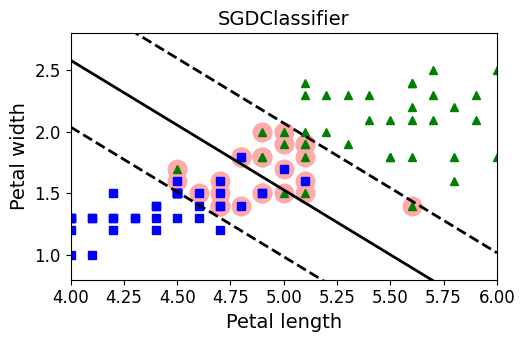

In [69]:
from sklearn.linear_model import SGDClassifier

#sgd_clf = SGDClassifier(loss="hinge", alpha = 0.017, n_iter = 50, random_state=42)
sgd_clf = SGDClassifier(loss="hinge", alpha = 0.017, max_iter= 1000 ,random_state=42)
#sgd_clf = SGDClassifier(loss="hinge", alpha = 0.017, random_state=42)
sgd_clf.fit(X, y.ravel())

m = len(X)
t = y * 2 - 1  # -1 if t==0, +1 if t==1
X_b = np.c_[np.ones((m, 1)), X]  # Add bias input x0=1
X_b_t = X_b * t
sgd_theta = np.r_[sgd_clf.intercept_[0], sgd_clf.coef_[0]]
print(sgd_theta)
support_vectors_idx = (X_b_t.dot(sgd_theta) < 1).ravel()
sgd_clf.support_vectors_ = X[support_vectors_idx]
sgd_clf.C = C

plt.figure(figsize=(5.5,3.2))
plt.plot(X[:, 0][yr==1], X[:, 1][yr==1], "g^")
plt.plot(X[:, 0][yr==0], X[:, 1][yr==0], "bs")
plot_svc_decision_boundary(sgd_clf, 4, 6)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.title("SGDClassifier", fontsize=14)
plt.axis([4, 6, 0.8, 2.8])

#### Reinstanciación del Clasificador SGD

La reinstanciación posterior del SGDClassifier con idénticos hiperparámetros demuestra la reproducibilidad del proceso y proporciona un modelo listo para despliegue o evaluación adicional. Esta separación entre desarrollo conceptual y implementación operativa refleja las mejores prácticas en flujos de trabajo de machine learning, donde los modelos validados se conservan para uso posterior sin modificación de sus parámetros fundamentales.

In [70]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(loss="hinge", alpha = 0.017, max_iter= 1000 ,random_state=42)

## Ejercicio 3

### Estudie el algoritmo de K- Nearest, con todo detalle mejore su documentación y con base en el haga cambios para una aplicación.

Introducción

La clase PongAgent implementa un agente de aprendizaje por refuerzo que utiliza el algoritmo Q-learning para desarrollar una política de control óptima en el entorno del juego Pong. Este agente emplea una tabla Q para almacenar y actualizar los valores de utilidad de las distintas combinaciones estado-acción.

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint
from time import sleep
from IPython.display import clear_output
from math import ceil,floor

%matplotlib inline

#### Arquitectura del Agente

**Inicialización**: El constructor de la clase inicializa los parámetros fundamentales del algoritmo de Q-learning. La tabla Q puede ser inicializada con valores proporcionados o creada como una matriz de ceros con dimensiones correspondientes al espacio de estados del juego y al espacio de acciones disponibles. Los parámetros de configuración incluyen el factor de descuento para recompensas futuras, la tasa de aprendizaje para actualizaciones de la tabla Q, y el ratio de explotación que determina la estrategia de exploración versus explotación.

**Mecanismo de Selección de Acciones** El método `get_next_step` implementa una política ε-greedy para la selección de acciones. Con probabilidad determinada por el ratio de explotación, el agente selecciona la acción con mayor valor Q para el estado actual (explotación del conocimiento adquirido). En los casos restantes, elige una acción aleatoria del espacio de acciones (exploración del entorno). Cuando existen múltiples acciones con el mismo valor Q máximo, la selección se realiza de forma aleatoria entre estas opciones óptimas.

**Actualización de la Política**: El método `update` implementa la regla de actualización del algoritmo Q-learning. Calcula la diferencia temporal entre la recompensa observada más el valor Q máximo del estado siguiente (descontado) y el valor Q actual de la acción tomada. Esta diferencia, ponderada por la tasa de aprendizaje, se utiliza para ajustar iterativamente los valores en la tabla Q. En estados terminales, el cálculo considera únicamente la recompensa inmediata recibida.

**Funcionalidades de Visualización y Acceso**: La clase proporciona métodos auxiliares para la inspección y recuperación de la política aprendida. `print_policy` genera una representación visual formateada de la tabla Q con valores redondeados, mientras que `get_policy` permite el acceso directo a la estructura de datos subyacente que almacena los valores Q.

**Fundamentos Algorítmicos**: El agente opera bajo el paradigma de Q-learning, un algoritmo de diferencias temporales que aproxima iterativamente la función de valor acción-estado óptima. La convergencia hacia la política óptima está garantizada bajo condiciones apropiadas de selección de parámetros y estrategia de exploración, cumpliendo con los principios establecidos en la teoría de aprendizaje por refuerzo para procesos de decisión markovianos.

In [72]:
class PongAgent:

    def __init__(self, game, policy=None, discount_factor = 0.1, learning_rate = 0.1, ratio_explotacion = 0.9):

        # Creamos la tabla de politicas
        if policy is not None:
            self._q_table = policy
        else:
            position = list(game.positions_space.shape)
            position.append(len(game.action_space))
            self._q_table = np.zeros(position)

        self.discount_factor = discount_factor
        self.learning_rate = learning_rate
        self.ratio_explotacion = ratio_explotacion

    def get_next_step(self, state, game):

        # Damos un paso aleatorio...
        next_step = np.random.choice(list(game.action_space))

        # o tomaremos el mejor paso...
        if np.random.uniform() <= self.ratio_explotacion:
            # tomar el maximo
            idx_action = np.random.choice(np.flatnonzero(
                    self._q_table[state[0],state[1],state[2]] ==
                self._q_table[state[0],state[1],state[2]].max()
                ))
            next_step = list(game.action_space)[idx_action]

        return next_step

    # actualizamos las politicas con las recompensas obtenidas
    def update(self, game, old_state, action_taken, reward_action_taken, new_state, reached_end):
        idx_action_taken =list(game.action_space).index(action_taken)

        actual_q_value_options = self._q_table[old_state[0], old_state[1], old_state[2]]
        actual_q_value = actual_q_value_options[idx_action_taken]

        future_q_value_options = self._q_table[new_state[0], new_state[1], new_state[2]]
        future_max_q_value = reward_action_taken  +  self.discount_factor*future_q_value_options.max()
        if reached_end:
            future_max_q_value = reward_action_taken #maximum reward

        self._q_table[old_state[0], old_state[1], old_state[2], idx_action_taken] = actual_q_value + \
                                              self.learning_rate*(future_max_q_value -actual_q_value)

    def print_policy(self):
        for row in np.round(self._q_table,1):
            for column in row:
                print('[', end='')
                for value in column:
                    print(str(value).zfill(5), end=' ')
                print('] ', end='')
            print('')

    def get_policy(self):
        return self._q_table

#### Arquitectura del entorno

La clase PongEnvironment implementa un entorno de simulación para el juego Pong que sirve como plataforma para el entrenamiento de agentes de aprendizaje por refuerzo. Este entorno modela la física del juego, gestiona las interacciones entre los elementos y proporciona las interfaces necesarias para la integración con algoritmos de RL.

**Inicialización y Configuración**: El constructor establece los parámetros fundamentales del juego, incluyendo las dimensiones del área de juego en píxeles, la velocidad de movimiento de los elementos y el número máximo de vidas. Se define un espacio de acciones discreto que permite el movimiento vertical de la paleta. El entorno inicializa el estado del juego mediante coordenadas discretizadas que representan las posiciones relativas de la paleta y la pelota.

**Gestión del Estado del Juego**: El método `reset` reinicia el entorno a un estado inicial aleatorio, restableciendo las vidas, la puntuación y las posiciones de los elementos. Retorna el estado inicial para permitir el inicio de nuevos episodios de entrenamiento. El método `step` ejecuta una acción específica del agente, actualiza el estado del entorno y retorna la tripleta estado-recompensa-terminación requerida por los algoritmos de RL.

**Mecánica de Simulación**: El método `_apply_action` traduce las acciones discretas del agente en movimientos concretos de la paleta, aplicando restricciones físicas para mantener los elementos dentro de los límites del juego. Posteriormente, actualiza la posición de la pelota y calcula el nuevo estado discretizado del sistema.

**Detección de Colisiones y Física del Juego**: La función `detectaColision` implementa la lógica de detección de colisiones entre la pelota y la paleta, considerando las dimensiones de ambos elementos y sus posiciones relativas. El método `avanza_frame` gestiona el movimiento de la pelota, el rebote en los bordes superior e inferior, y la interacción con la paleta del jugador. Cuando la pelota alcanza el borde izquierdo, se verifica la colisión y se asignan recompensas positivas por interceptaciones exitosas o penalizaciones por fallos.

**Sistema de Recompensas y Terminación**: El entorno implementa un sistema de recompensas que asigna +10 puntos por interceptaciones exitosas de la pelota y -10 puntos por fallos, con una penalización adicional por paso para incentivar la eficiencia. La terminación del episodio ocurre cuando se agotan todas las vidas disponibles. El cálculo de recompensas considera tanto la puntuación inmediata como las penalizaciones acumuladas.

**Visualización y Renderizado**: El método `dibujar_frame` genera una representación gráfica del estado actual del juego utilizando matplotlib, mostrando la paleta controlada por el agente, la pelota en movimiento, y la información relevante como puntuación total y vidas restantes. Incluye mensajes de estado para condiciones terminales como "GAME OVER" o "YOU WIN" cuando se alcanzan los criterios de finalización.

**Características de Diseño**: El entorno emplea discretización espacial basada en la velocidad de movimiento para reducir la dimensionalidad del espacio de estados, facilitando el aprendizaje del agente. La física simplificada mantiene la esencia del juego mientras garantiza la eficiencia computacional necesaria para procesos iterativos de entrenamiento. La implementación proporciona interfaces estándar compatibles con frameworks de aprendizaje por refuerzo, permitiendo la integración transparente con diferentes algoritmos de RL.

In [73]:
class PongEnvironment:

    def __init__(self, max_life=3, height_px = 40, width_px = 50, movimiento_px = 3):

        self.action_space = ['Arriba','Abajo']

        self._step_penalization = 0

        self.state = [0,0,0]

        self.total_reward = 0

        self.dx = movimiento_px
        self.dy = movimiento_px

        filas = ceil(height_px/movimiento_px)
        columnas = ceil(width_px/movimiento_px)

        self.positions_space = np.array([[[0 for z in range(columnas)]
                                                  for y in range(filas)]
                                                     for x in range(filas)])

        self.lives = max_life
        self.max_life=max_life

        self.x = randint(int(width_px/2), width_px)
        self.y = randint(0, height_px-10)

        self.player_alto = int(height_px/4)

        self.player1 = self.player_alto  # posic. inicial del player

        self.score = 0

        self.width_px = width_px
        self.height_px = height_px
        self.radio = 2.5

    def reset(self):
        self.total_reward = 0
        self.state = [0,0,0]
        self.lives = self.max_life
        self.score = 0
        self.x = randint(int(self.width_px/2), self.width_px)
        self.y = randint(0, self.height_px-10)
        return self.state

    def step(self, action, animate=False):
        self._apply_action(action, animate)
        done = self.lives <=0 # final
        reward = self.score
        reward += self._step_penalization
        self.total_reward += reward
        return self.state, reward , done

    def _apply_action(self, action, animate=False):

        if action == "Arriba":
            self.player1 += abs(self.dy)
        elif action == "Abajo":
            self.player1 -= abs(self.dy)

        self.avanza_player()

        self.avanza_frame()

        if animate:
            clear_output(wait=True);
            fig = self.dibujar_frame()
            plt.show()

        self.state = (floor(self.player1/abs(self.dy))-2, floor(self.y/abs(self.dy))-2, floor(self.x/abs(self.dx))-2)

    def detectaColision(self, ball_y, player_y):
        if (player_y+self.player_alto >= (ball_y-self.radio)) and (player_y <= (ball_y+self.radio)):
            return True
        else:
            return False

    def avanza_player(self):
        if self.player1 + self.player_alto >= self.height_px:
            self.player1 = self.height_px - self.player_alto
        elif self.player1 <= -abs(self.dy):
            self.player1 = -abs(self.dy)

    def avanza_frame(self):
        self.x += self.dx
        self.y += self.dy
        if self.x <= 3 or self.x > self.width_px:
            self.dx = -self.dx
            if self.x <= 3:
                ret = self.detectaColision(self.y, self.player1)

                if ret:
                    self.score = 10
                else:
                    self.score = -10
                    self.lives -= 1
                    if self.lives>0:
                        self.x = randint(int(self.width_px/2), self.width_px)
                        self.y = randint(0, self.height_px-10)
                        self.dx = abs(self.dx)
                        self.dy = abs(self.dy)
        else:
            self.score = 0

        if self.y < 0 or self.y > self.height_px:
            self.dy = -self.dy

    def dibujar_frame(self):
        fig = plt.figure(figsize=(5, 4))
        a1 = plt.gca()
        circle = plt.Circle((self.x, self.y), self.radio, fc='slategray', ec="black")
        a1.set_ylim(-5, self.height_px+5)
        a1.set_xlim(-5, self.width_px+5)

        rectangle = plt.Rectangle((-5, self.player1), 5, self.player_alto, fc='gold', ec="none")
        a1.add_patch(circle);
        a1.add_patch(rectangle)
        #a1.set_yticklabels([]);a1.set_xticklabels([]);
        plt.text(4, self.height_px, "SCORE:"+str(self.total_reward)+"  LIFE:"+str(self.lives), fontsize=12)
        if self.lives <=0:
            fig = plt.text(10, self.height_px-14, "GAME OVER", fontsize=16)
        elif self.total_reward >= 1000:
            fig = plt.text(10, self.height_px-14, "YOU WIN!", fontsize=16)
        return fig

#### Entrenamiento

La función `play` implementa el ciclo principal de entrenamiento para el agente de Pong mediante aprendizaje por refuerzo. Esta función orquesta la interacción entre el entorno de simulación y el agente inteligente, gestionando múltiples episodios de entrenamiento mientras recopila métricas de rendimiento y facilita el proceso de aprendizaje.

**Parámetros de Entrenamiento**:

- `rounds`: Especifica el número total de episodios de entrenamiento a ejecutar. Valor por defecto: 5000

- `max_life`: Define el número máximo de vidas disponibles por episodio. Valor por defecto: 3

- `discount_factor`: Factor de descuento para recompensas futuras en el algoritmo Q-learning. Valor por defecto: 0.1

- `learning_rate`: Tasa de aprendizaje que determina la velocidad de actualización de la tabla Q. Valor por defecto: 0.1

- `ratio_explotacion`: Proporción entre explotación y exploración en la política ε-greedy. Valor por defecto: 0.9

**Parámetros de Instanciación**:

- `learner`: Permite la utilización de un agente previamente entrenado para continuar el aprendizaje o evaluación

- `game`: Posibilita la reutilización de un entorno de juego existente con configuraciones específicas

- `animate`: Controla la visualización en tiempo real del proceso de entrenamiento. Valor por defecto: False

**Mecánica de Ejecución**:

Cuando no se proporcionan instancias existentes, la función inicializa un nuevo entorno de Pong con discretización espacial basada en movimiento de 3 píxeles, generando una tabla de políticas de dimensiones 14x17. Simultáneamente, crea un nuevo agente con los parámetros de aprendizaje especificados.

La función ejecuta un número predeterminado de episodios, donde cada episodio representa una partida completa de Pong. Para cada episodio:

- Reinicia el entorno al estado inicial

- Itera hasta 3000 pasos o hasta alcanzar una recompensa acumulada de 1000 puntos

- Selecciona acciones mediante la política ε-greedy del agente

- Aplica las acciones al entorno y observa las transiciones de estado

- Actualiza la tabla Q del agente utilizando la regla de actualización de Q-learning

Cada episodio finaliza cuando se agotan las vidas del agente, se excede el límite de pasos o se alcanza la condición de victoria. La función implementa criterios de terminación múltiples para garantizar la eficiencia computacional durante el entrenamiento extensivo.

#### Monitoreo y Métricas

**Seguimiento de Rendimiento**:
La función recopila métricas comprehensivas durante el proceso de entrenamiento, incluyendo:

- Puntuación máxima alcanzada y el episodio en que se obtuvo

- Promedio de pasos por episodio

- Recompensa acumulada promedio

- Número de iteraciones por episodio

- Reporte de Progreso

Cada 500 episodios, la función genera reportes intermedios que muestran el progreso del entrenamiento, permitiendo la monitorización del aprendizaje y la detección temprana de problemas de convergencia. Al finalizar el entrenamiento, se presenta un resumen consolidado con las estadísticas finales.

**Retorno y Productos**: 

La función retorna una tupla conteniendo el agente entrenado y el entorno utilizado, permitiendo:

- La continuación del entrenamiento en sesiones posteriores

- La evaluación del agente en condiciones controladas

- El análisis de la política aprendida mediante inspección directa

- La reutilización del conocimiento adquirido en escenarios aplicados

La implementación soporta tanto entrenamiento intensivo como demostraciones visuales, manteniendo separación clara entre la lógica de aprendizaje y la interfaz de usuario.

In [76]:
def play(rounds=5000, max_life=3, discount_factor = 0.1, learning_rate = 0.1,
         ratio_explotacion=0.9,learner=None, game=None, animate=False):

    if game is None:
        # si usamos movimiento_px = 5 creamos una tabla de politicas de 8x10
        # si usamos movimiento_px = 3 la tabla sera de 14x17
        game = PongEnvironment(max_life=max_life, movimiento_px = 3)

    if learner is None:
        print("Begin new Train!")
        learner = PongAgent(game, discount_factor = discount_factor,learning_rate = learning_rate, ratio_explotacion= ratio_explotacion)

    max_points= -9999
    first_max_reached = 0
    total_rw=0
    steps=[]

    for played_games in range(0, rounds):
        state = game.reset()
        reward, done = None, None

        itera=0
        while (done != True) and (itera < 3000 and game.total_reward<=1000):
            old_state = np.array(state)
            next_action = learner.get_next_step(state, game)
            state, reward, done = game.step(next_action, animate=animate)
            if rounds > 1:
                learner.update(game, old_state, next_action, reward, state, done)
            itera+=1

        steps.append(itera)

        total_rw+=game.total_reward
        if game.total_reward > max_points:
            max_points=game.total_reward
            first_max_reached = played_games

        if played_games %500==0 and played_games >1 and not animate:
            print("-- Partidas[", played_games, "] Avg.Puntos[", int(total_rw/played_games),"]  AVG Pasos[", int(np.array(steps).mean()), "] Max Score[", max_points,"]")

    if played_games>1:
        print('Partidas[',played_games,'] Avg.Puntos[',int(total_rw/played_games),'] Max score[', max_points,'] en partida[',first_max_reached,']')

    #learner.print_policy()

    return learner, game

#### Configuración de Hiperparámetros

El proceso de entrenamiento se inicializa ejecutando la función play con los siguientes parámetros específicos:

- `rounds=5000`: Ciclo de entrenamiento extenso de 5000 episodios para permitir convergencia adecuada

- `discount_factor=0.2`: Factor de descuento moderado que prioriza recompensas inmediatas sobre las futuras

- `learning_rate=0.1`: Tasa de aprendizaje estándar que balancea estabilidad y velocidad de adaptación

- `ratio_explotacion=0.85`: Alto ratio de explotación que favorece la utilización del conocimiento adquirido mientras mantiene exploración mínima

Durante esta fase, el agente interactúa con el entorno a través de múltiples episodios, actualizando iterativamente su tabla Q mediante el algoritmo de Q-learning. El proceso opera en modo no animado para maximizar el rendimiento computacional, priorizando la eficiencia sobre la visualización. Los reportes periódicos generados cada 500 episodios permiten monitorear el progreso del aprendizaje, incluyendo métricas de puntuación promedio, número de pasos y rendimiento máximo alcanzado.

In [77]:
learner, game = play(rounds=5000, discount_factor = 0.2, learning_rate = 0.1, ratio_explotacion=0.85)

Begin new Train!
-- Partidas[ 500 ] Avg.Puntos[ 21 ]  AVG Pasos[ 243 ] Max Score[ 170 ]
-- Partidas[ 1000 ] Avg.Puntos[ 26 ]  AVG Pasos[ 257 ] Max Score[ 170 ]
-- Partidas[ 1500 ] Avg.Puntos[ 27 ]  AVG Pasos[ 261 ] Max Score[ 260 ]
-- Partidas[ 2000 ] Avg.Puntos[ 28 ]  AVG Pasos[ 265 ] Max Score[ 260 ]
-- Partidas[ 2500 ] Avg.Puntos[ 30 ]  AVG Pasos[ 273 ] Max Score[ 300 ]
-- Partidas[ 3000 ] Avg.Puntos[ 32 ]  AVG Pasos[ 281 ] Max Score[ 320 ]
-- Partidas[ 3500 ] Avg.Puntos[ 35 ]  AVG Pasos[ 291 ] Max Score[ 320 ]
-- Partidas[ 4000 ] Avg.Puntos[ 39 ]  AVG Pasos[ 302 ] Max Score[ 370 ]
-- Partidas[ 4500 ] Avg.Puntos[ 42 ]  AVG Pasos[ 313 ] Max Score[ 520 ]
Partidas[ 4999 ] Avg.Puntos[ 44 ] Max score[ 520 ] en partida[ 4077 ]


#### Evaluación del Agente Entrenado

Se instancia un nuevo agente (learner2) que hereda directamente la política óptima adquirida durante el entrenamiento mediante el parámetro policy=learner.get_policy(). Este enfoque permite separar claramente la fase de aprendizaje de la fase de evaluación, evitando modificaciones accidentales de la política durante la demostración.

**Configuración para Evaluación**: 

- `ratio_explotacion=1.0`: Configuración crítica que desactiva completamente la exploración aleatoria, forzando al agente a seleccionar exclusivamente las acciones óptimas según su política aprendida

- `rounds=1`: Ejecución de un único episodio de demostración

- `animate=True`: Activación del renderizado gráfico en tiempo real para visualizar el comportamiento del agente

Esta fase permite:

- La validación cualitativa del desempeño del agente entrenado

- La demostración visual de las estrategias aprendidas

- La verificación de que el agente ha desarrollado comportamientos efectivos para interceptar la pelota y maximizar su puntuación

- La confirmación de que la política aprendida es estable y reproducible

El proceso completo ejemplifica la metodología estándar en aprendizaje por refuerzo, donde un período extenso de entrenamiento sin visualización es seguido por sesiones de evaluación con renderizado completo para verificar los resultados.

In [78]:
learner2 = PongAgent(game, policy=learner.get_policy())
learner2.ratio_explotacion = 1.0  # con esto quitamos las elecciones aleatorias al jugar
player = play(rounds=1, learner=learner2, game=game, animate=True)

KeyboardInterrupt: 

<Figure size 500x400 with 0 Axes>

## Ejercicio 4

### Estudie el algoritmo de Bayes ingenuo y haga n ejemplo bien documentado.

El algoritmo Naive Bayes es un clasificador probabilístico basado en el teorema de Bayes, que asume que las características son independientes entre sí dada la clase. Es eficiente, fácil de implementar y funciona bien en problemas como filtrado de spam, diagnóstico médico y análisis de sentimientos.

El fundamento de este método de Machine Learning es el Teorema de bayes:
$$P (A|B) = \frac{P(A)*P(B|A)}{P(B)} $$
Este teorema es uno de los teoremas más fundamentales de la estadística de la historia, sentando las bases para entender el comportamiento de las probabilidades dado los casos en que las probabilidades de dos eventos A y B sean dependientes de sus ocurrencias entre ellos.

La clave del "ingenuo" (naive) es la suposición de que las características son condicionalmente independientes dada la clase:

$$P(X_1, X_2, ..., X_n|Y) = \prod_{i=1}^{n} P(X_i|Y)$$
Esto simplifica enormemente el cálculo, permitiendo tratar cada característica por separado. Por ejemplo, para clasificar una nueva instancia $X = (x_₁, x_₂, ..., x_ₙ)$, calculamos:

$$P(Y=k|X) \propto P(Y=k) \cdot \prod_{i=1}^{n} P(X_i=x_i|Y=k)$$

Y seleccionamos la clase con mayor probabilidad posterior:

$$\hat{Y} = \arg\max_{k} \left[ P(Y=k) \cdot \prod_{i=1}^{n} P(X_i=x_i|Y=k) \right]$$

#### Tipos de Distribuciones en Naive Bayes

1. **Multinomial** (para conteos/frecuencias)

$$P(X_i|Y=k) = \frac{\text{count}(X_i, Y=k) + \alpha}{\sum_{j}\text{count}(X_j, Y=k) + \alpha \cdot |V|}$$
2. **Gaussiana** (para características continuas)

$$P(X_i|Y=k) = \frac{1}{\sqrt{2\pi\sigma_k^2}} \exp\left(-\frac{(x_i - \mu_k)^2}{2\sigma_k^2}\right)$$
3. **Bernoulli** (para características binarias)

$$P(X_i|Y=k) = p_{k}^{x_i} \cdot (1-p_k)^{1-x_i}$$

#### Manejo de Underflow Numérico
En la práctica, usamos log-probabilities para evitar underflow:

$$\log P(Y=k|X) \propto \log P(Y=k) + \sum_{i=1}^{n} \log P(X_i=x_i|Y=k)$$

$$\hat{Y} = \arg\max_{k} \left[ \log P(Y=k) + \sum_{i=1}^{n} \log P(X_i=x_i|Y=k) \right]$$

La clave del Naive Bayes, es que aprende los parámetros óptimos del modelo a partir del entrenamiento. El objetivo global del modelo es estimar la probabilidad de una variable poblacional desconocida, a partir de probabilidades conocidas de características relacionadas, y la probabilidad condicional correspondiente. Al final del entrenamientom este modelo puede hacer predicciones sobre datos no vistos previamente. Esto se puede observar por el pipeline de entrenamiento tradicional del modelo:

1. Calcular probabilidad de los features P(Y)
`class_probs = {cls: count / total_samples}`

2. Calcular probabilidad condicional P(X|Y)
`for word in vocabulary:
    feature_probs[cls]['word_freq'][word] = count / total_words`

3. Estimar parámetros de distribuciones
`feature_probs[cls]['message_length'] = {'mean': np.mean(lengths), 'std': np.std(lengths)}`

4. Combinar evidencias usando teorema de Bayes
`score = log(P(Y)) + Σ log(P(X_i|Y))
prediction = argmax(score)`

Para finalizar, se deben anotar las principales ventajas y desventajas de este algoritmo La principal ventaja, es que es uno de los algoritmos de ML más computacionalmente eficiente, con el tiempo de predicción demostrado que cumple con una cota superior O(n). La suposición de independencia de features de baja probabilidad de ocurrencia le da ventaja adicional en los cálculos de problemas de alta dimensionalidad. Las características individuales tienen impacto limitado, por lo que es robusto al ruido. Y los resultados son fáciles de interpretar para un público objetivo no técnico. Por otro lado, como se fundamenta en una suposición de independencia que, limita la complejidad, pero es arbitraria, puede introducir sesgos y reducir la varianza de las predicciones obtenidas.

In [83]:
import pandas as pd
import numpy as np
import math
from collections import defaultdict, Counter
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Para este ejercicio, vamos a utilizar este algoritmo para simular un detector de correos spam usando un clasificador de tipo Naive Bayes. 

Introducimos un método de preprocesado de texto (`preprocess_text`) para ignorar caracteres especiales, y concentrarnos específicamente en las palabras con significado semántico. El parámetro de clase `alpha` es el suavizado de Laplace, y es un hiperparámetro usado internamente para prevenir el overfitting del modelo. Los métodos `extract_features` y `fit` nos permiten extraer los datos de probabilidad condicional, y entrenar los parámetros del modelo, respectivamente. Nuestro Clasificador de Bayes maneja distribuciones gaussianas, por lo que usamos el método `_gaussian_probability` para calcular la media y desviación estándar de los datos usados para el entrenamiento. Finalmente, definimos los métodos de predicción, basados en el Teorema de Bayes y la suposición de independencia explicadas anteriormente para retornar la predicción final.

In [87]:
class NaiveBayesSpamClassifier:
    """
    Implementación completa de Naive Bayes para clasificación de spam
    con múltiples características: frecuencia de palabras, longitud del mensaje,
    presencia de caracteres especiales, etc.
    """
    
    def __init__(self, alpha=1.0):
        """
        Inicializa el clasificador
        
        Args:
            alpha: Parámetro de suavizado de Laplace
        """
        self.alpha = alpha
        self.class_probs = {}
        self.feature_probs = {}
        self.vocabulary = set()
        self.classes = []
        
    def preprocess_text(self, text):
        """
        Preprocesamiento de texto: limpieza y tokenización
        """
        # Convertir a minúsculas y eliminar caracteres especiales
        text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
        # Tokenizar
        tokens = text.split()
        return tokens
    
    def extract_features(self, text):
        """
        Extrae múltiples características del texto
        """
        tokens = self.preprocess_text(text)
        
        # Evitar división por cero en uppercase_ratio
        text_length = len(text) if len(text) > 0 else 1
        
        features = {
            'word_freq': Counter(tokens),
            'message_length': len(text),
            'word_count': len(tokens),
            'has_exclamation': 1 if '!' in text else 0,
            'has_urgent_words': 1 if any(word in text.lower() for word in ['urgent', 'immediately', 'asap']) else 0,
            'has_links': 1 if re.search(r'http[s]?://', text) else 0,
            'uppercase_ratio': sum(1 for c in text if c.isupper()) / text_length
        }
        
        return features
    
    def fit(self, X, y):
        """
        Entrena el modelo Naive Bayes
        
        Args:
            X: Lista de mensajes de texto
            y: Lista de etiquetas (0: no spam, 1: spam)
        """
        self.classes = list(set(y))
        
        # 1. Calcular probabilidades a priori de las clases
        class_counts = Counter(y)
        total_samples = len(y)
        self.class_probs = {cls: count / total_samples for cls, count in class_counts.items()}
        
        # 2. Construir vocabulario y extraer características
        all_features = []
        for text in X:
            features = self.extract_features(text)
            all_features.append(features)
            self.vocabulary.update(features['word_freq'].keys())
        
        # 3. Calcular probabilidades de características para cada clase
        self.feature_probs = {cls: defaultdict(lambda: defaultdict(float)) for cls in self.classes}
        
        # Para características categóricas (palabras)
        for cls in self.classes:
            # Filtrar mensajes por clase
            class_indices = [i for i in range(len(X)) if y[i] == cls]
            class_texts = [X[i] for i in class_indices]
            class_features = [all_features[i] for i in class_indices]
            
            # Calcular frecuencias de palabras
            word_counts = Counter()
            for features in class_features:
                word_counts.update(features['word_freq'])
            
            total_words = sum(word_counts.values())
            vocab_size = len(self.vocabulary)
            
            # Probabilidades suavizadas para palabras
            for word in self.vocabulary:
                count = word_counts[word] + self.alpha
                self.feature_probs[cls]['word_freq'][word] = count / (total_words + self.alpha * vocab_size)
            
            # Probabilidades para características numéricas (asumiendo distribución normal)
            # Longitud del mensaje
            if class_features:  # Verificar que hay datos
                lengths = [features['message_length'] for features in class_features]
                self.feature_probs[cls]['message_length'] = {
                    'mean': np.mean(lengths),
                    'std': max(np.std(lengths), 0.1)  # Evitar desviación estándar cero
                }
                
                # Conteo de palabras
                word_counts_list = [features['word_count'] for features in class_features]
                self.feature_probs[cls]['word_count'] = {
                    'mean': np.mean(word_counts_list),
                    'std': max(np.std(word_counts_list), 0.1)
                }
                
                # Ratio de mayúsculas
                uppercase_ratios = [features['uppercase_ratio'] for features in class_features]
                self.feature_probs[cls]['uppercase_ratio'] = {
                    'mean': np.mean(uppercase_ratios),
                    'std': max(np.std(uppercase_ratios), 0.01)
                }
                
                # Probabilidades para características binarias
                binary_features = ['has_exclamation', 'has_urgent_words', 'has_links']
                for feature in binary_features:
                    feature_values = [features[feature] for features in class_features]
                    prob_1 = (sum(feature_values) + self.alpha) / (len(feature_values) + 2 * self.alpha)
                    self.feature_probs[cls][feature] = {
                        0: max(1 - prob_1, 1e-10),  # Evitar probabilidades cero
                        1: max(prob_1, 1e-10)
                    }
            else:
                # Si no hay datos para esta clase, usar valores por defecto
                self.feature_probs[cls]['message_length'] = {'mean': 0, 'std': 1}
                self.feature_probs[cls]['word_count'] = {'mean': 0, 'std': 1}
                self.feature_probs[cls]['uppercase_ratio'] = {'mean': 0, 'std': 0.1}
                for feature in ['has_exclamation', 'has_urgent_words', 'has_links']:
                    self.feature_probs[cls][feature] = {0: 0.5, 1: 0.5}
    
    def _gaussian_probability(self, x, mean, std):
        """Calcula la probabilidad usando distribución normal con protección contra underflow"""
        if std < 1e-6:  # Evitar desviación estándar cero
            std = 0.1
            
        exponent = -((x - mean) ** 2) / (2 * std ** 2)
        # Usar log probabilities para evitar underflow numérico
        log_prob = -0.5 * math.log(2 * math.pi * std ** 2) + exponent
        return log_prob
    
    def _safe_log(self, value):
        """Calcula el logaritmo de forma segura evitando math domain error"""
        return math.log(max(value, 1e-10))
    
    def predict_proba(self, X):
        """
        Predice probabilidades para cada clase
        """
        predictions = []
        
        for text in X:
            features = self.extract_features(text)
            class_scores = {}
            
            for cls in self.classes:
                # Iniciar con la probabilidad a priori (en log)
                score = self._safe_log(self.class_probs[cls])
                
                # Probabilidad de palabras (características multinomiales)
                for word, count in features['word_freq'].items():
                    if word in self.feature_probs[cls]['word_freq']:
                        word_prob = self.feature_probs[cls]['word_freq'][word]
                        score += count * self._safe_log(word_prob)
                
                # Probabilidad de características numéricas (usando log probabilities)
                # Longitud del mensaje
                length_log_prob = self._gaussian_probability(
                    features['message_length'],
                    self.feature_probs[cls]['message_length']['mean'],
                    self.feature_probs[cls]['message_length']['std']
                )
                score += length_log_prob
                
                # Conteo de palabras
                word_count_log_prob = self._gaussian_probability(
                    features['word_count'],
                    self.feature_probs[cls]['word_count']['mean'],
                    self.feature_probs[cls]['word_count']['std']
                )
                score += word_count_log_prob
                
                # Ratio de mayúsculas
                uppercase_log_prob = self._gaussian_probability(
                    features['uppercase_ratio'],
                    self.feature_probs[cls]['uppercase_ratio']['mean'],
                    self.feature_probs[cls]['uppercase_ratio']['std']
                )
                score += uppercase_log_prob
                
                # Probabilidad de características binarias
                binary_features = ['has_exclamation', 'has_urgent_words', 'has_links']
                for feature in binary_features:
                    feature_value = features[feature]
                    prob = self.feature_probs[cls][feature].get(feature_value, 1e-10)
                    score += self._safe_log(prob)
                
                class_scores[cls] = score
            
            # Convertir scores logarítmicos a probabilidades
            max_score = max(class_scores.values())
            exp_scores = {cls: math.exp(score - max_score) for cls, score in class_scores.items()}
            total = sum(exp_scores.values())
            
            # Evitar división por cero
            if total == 0:
                probabilities = {cls: 1.0 / len(self.classes) for cls in self.classes}
            else:
                probabilities = {cls: exp_scores[cls] / total for cls in self.classes}
            
            predictions.append(probabilities)
        
        return predictions
    
    def predict(self, X):
        """
        Predice la clase más probable
        """
        probabilities = self.predict_proba(X)
        predictions = [max(probs.items(), key=lambda x: x[1])[0] for probs in probabilities]
        return predictions

Una vez definido nuestro clasificador, vamos a simular un dataset de correos spam y no spam, para determinar si Bayes es capaz de distinguirlos por medio de aprendizaje supervisado, y más importante, definir cuáles son los parámetros que usa en caso de que sea exitoso.

In [88]:
def generate_sample_data(n_samples=1000):
    """
    Genera un dataset sintético más complejo para clasificación de spam
    """
    np.random.seed(42)
    
    # Patrones típicos de spam
    spam_patterns = [
        "urgent win free money prize",
        "click link special offer limited",
        "congratulations you won lottery",
        "urgent account verification required",
        "free gift card exclusive deal",
        "money back guarantee special promotion",
        "limited time offer buy now",
        "risk free investment opportunity",
        "exclusive membership bonus reward",
        "instant approval credit card"
    ]
    
    # Patrones típicos de no spam (ham)
    ham_patterns = [
        "meeting scheduled for tomorrow office",
        "lunch together next week restaurant",
        "project update status report",
        "family dinner weekend plans",
        "weather forecast sunny day",
        "movie night friends cinema",
        "grocery shopping list items",
        "work presentation preparation slides",
        "weekend trip travel arrangements",
        "book club discussion next meeting"
    ]
    
    messages = []
    labels = []
    
    for i in range(n_samples):
        if np.random.random() < 0.5:  # 50% spam
            pattern = np.random.choice(spam_patterns)
            # Variar el mensaje añadiendo ruido
            if np.random.random() < 0.7:
                message = pattern.upper() + " !!! CLICK NOW !!!"
            else:
                message = pattern + " http://example.com"
            labels.append(1)  # Spam
        else:
            pattern = np.random.choice(ham_patterns)
            # Mensajes normales con menos énfasis
            message = pattern.capitalize() + "."
            labels.append(0)  # No spam
        
        messages.append(message)
    
    return messages, labels

Finalmente, probamos nuestro modelo, e imprimimos la matriz de confusión, así como el Análisis de Palabras Características para definir su método de predicción, en caso de que sea exitoso.

CLASIFICADOR DE SPAM CON NAIVE BAYES - EJEMPLO COMPLEJO

1. Generando dataset sintético...
Tamaño del dataset: 500 mensajes
Training: 350 mensajes
Test: 150 mensajes
Distribución de clases: Counter({0: 260, 1: 240})

2. Entrenando modelo Naive Bayes...

3. Realizando predicciones...

4. Evaluación del modelo:
----------------------------------------
              precision    recall  f1-score   support

     No Spam       1.00      1.00      1.00        78
        Spam       1.00      1.00      1.00        72

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



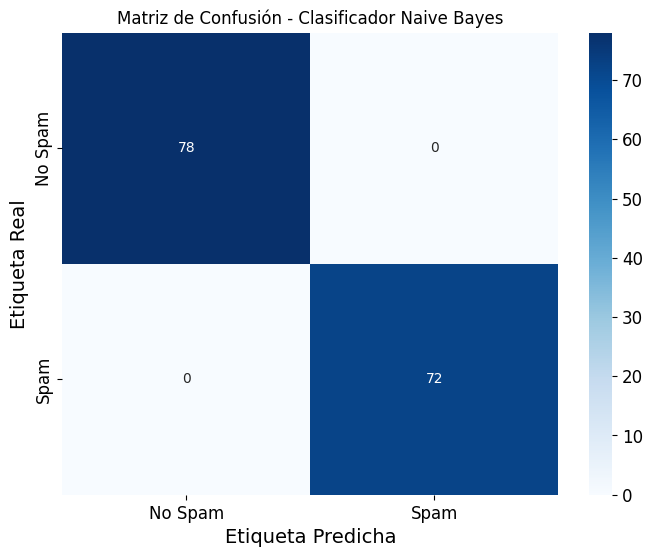


5. Ejemplos de predicción:
----------------------------------------

Mensaje 1: 'URGENT WIN FREE MONEY NOW CLICK LINK!!!'
  → Probabilidad No Spam: 0.00%
  → Probabilidad Spam: 100.00%
  → Clasificación: SPAM

Mensaje 2: 'Meeting tomorrow at 3pm in conference room'
  → Probabilidad No Spam: 10.64%
  → Probabilidad Spam: 89.36%
  → Clasificación: SPAM

Mensaje 3: 'Congratulations you won the lottery prize'
  → Probabilidad No Spam: 0.00%
  → Probabilidad Spam: 100.00%
  → Clasificación: SPAM

Mensaje 4: 'Lunch together next Friday?'
  → Probabilidad No Spam: 100.00%
  → Probabilidad Spam: 0.00%
  → Clasificación: NO SPAM

Mensaje 5: 'FREE GIFT CARD LIMITED TIME OFFER!!!'
  → Probabilidad No Spam: 0.00%
  → Probabilidad Spam: 100.00%
  → Clasificación: SPAM

Mensaje 6: 'The project status update is ready for review'
  → Probabilidad No Spam: 0.00%
  → Probabilidad Spam: 100.00%
  → Clasificación: SPAM

6. Análisis de palabras características:
----------------------------------------
Pal

In [89]:
def main():
    print("=" * 60)
    print("CLASIFICADOR DE SPAM CON NAIVE BAYES - EJEMPLO COMPLEJO")
    print("=" * 60)
    
    # 1. Generar datos
    print("\n1. Generando dataset sintético...")
    X, y = generate_sample_data(500)  # Reducido para prueba
    
    # 2. Dividir en entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    
    print(f"Tamaño del dataset: {len(X)} mensajes")
    print(f"Training: {len(X_train)} mensajes")
    print(f"Test: {len(X_test)} mensajes")
    print(f"Distribución de clases: {Counter(y)}")
    
    # 3. Entrenar el modelo
    print("\n2. Entrenando modelo Naive Bayes...")
    nb_classifier = NaiveBayesSpamClassifier(alpha=1.0)
    nb_classifier.fit(X_train, y_train)
    
    # 4. Realizar predicciones
    print("\n3. Realizando predicciones...")
    y_pred = nb_classifier.predict(X_test)
    y_pred_proba = nb_classifier.predict_proba(X_test)
    
    # 5. Evaluar el modelo
    print("\n4. Evaluación del modelo:")
    print("-" * 40)
    print(classification_report(y_test, y_pred, target_names=['No Spam', 'Spam']))
    
    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['No Spam', 'Spam'], 
                yticklabels=['No Spam', 'Spam'])
    plt.title('Matriz de Confusión - Clasificador Naive Bayes')
    plt.ylabel('Etiqueta Real')
    plt.xlabel('Etiqueta Predicha')
    plt.show()
    
    # 6. Ejemplos de predicción
    print("\n5. Ejemplos de predicción:")
    print("-" * 40)
    
    test_examples = [
        "URGENT WIN FREE MONEY NOW CLICK LINK!!!",
        "Meeting tomorrow at 3pm in conference room",
        "Congratulations you won the lottery prize",
        "Lunch together next Friday?",
        "FREE GIFT CARD LIMITED TIME OFFER!!!",
        "The project status update is ready for review"
    ]
    
    predictions = nb_classifier.predict_proba(test_examples)
    
    for i, (message, probs) in enumerate(zip(test_examples, predictions)):
        spam_prob = probs[1] * 100
        ham_prob = probs[0] * 100
        prediction = "SPAM" if spam_prob > ham_prob else "NO SPAM"
        
        print(f"\nMensaje {i+1}: '{message}'")
        print(f"  → Probabilidad No Spam: {ham_prob:.2f}%")
        print(f"  → Probabilidad Spam: {spam_prob:.2f}%")
        print(f"  → Clasificación: {prediction}")
    
    # 7. Análisis de características importantes
    print("\n6. Análisis de palabras características:")
    print("-" * 40)
    
    spam_words = {}
    ham_words = {}
    
    # Obtener las probabilidades de palabras más discriminativas
    vocabulary_list = list(nb_classifier.vocabulary)
    if vocabulary_list:  # Verificar que el vocabulario no esté vacío
        for word in vocabulary_list[:20]:  # Mostrar solo las primeras 20
            if word in nb_classifier.feature_probs[1]['word_freq'] and word in nb_classifier.feature_probs[0]['word_freq']:
                spam_prob = nb_classifier.feature_probs[1]['word_freq'][word]
                ham_prob = nb_classifier.feature_probs[0]['word_freq'][word]
                
                # Calcular ratio de verosimilitud
                if ham_prob > 0:
                    ratio = spam_prob / ham_prob
                    if ratio > 1:
                        spam_words[word] = ratio
        
        # Mostrar palabras más indicativas de spam
        if spam_words:
            print("Palabras más indicativas de SPAM (ratio spam/ham):")
            for word, ratio in sorted(spam_words.items(), key=lambda x: x[1], reverse=True)[:10]:
                print(f"  '{word}': {ratio:.2f}")
        else:
            print("No se encontraron palabras significativas para spam.")
    else:
        print("El vocabulario está vacío.")

if __name__ == "__main__":
    main()

Usando la semilla 42, podemos corroborar que con los datos sintéticos de entrada usados para este ejemplo, el Clasificador logra un índice de predicción del 100%, junto a 6 mensajes de prueba para corroborar su capacidad de predicción.

En el Análisis de Palabras Características, podemos observar que la palabra "click" fue la que mayor puntaje daba en la escala interna de posibilidad de spam, seguido de "now", y en un distante tercer lugar la palabra "free". Valga aclarar que estas palabras pueden cambiar en distintos datasets, y estas dos palabras en particular pueden ser frecuentes en correos laborales, ya sea porque tengan links para videoconferencias, o en mensajes de urgencia respecto a una entrega o una reunión. El valor particular de este algoritmo, no obstante, es lo fácil que es de adaptar a un flujo de datos variable en el tiempo, permitiéndole un entrenamiento constante para detectar nuevas tendencias de correos spam, lo que es particularmente valioso en el contexto de la evolución constante de los correos spam para poder evitar los detectores automáticos.